<div style="background: linear-gradient(135deg, #4F46E5 0%, #7C3AED 100%); color: white; padding: 30px 40px; border-radius: 12px; text-align: left; box-shadow: 0 10px 25px rgba(0, 0, 0, 0.1);">
        <h1 style="font-size: 2.8em; margin: 0; font-weight: 700; display: flex; align-items: center;">
            <span style="font-size: 1.2em; margin-right: 15px;">📊</span>Exploratory Data Analysis
        </h1>
        <p style="font-size: 1.3em; margin: 8px 0 0; opacity: 0.9;">
            Analyzing the Key Drivers of Customer Churn
        </p>
    </div>

<div style="background: linear-gradient(135deg, #4F46E5 0%, #7C3AED 100%);margin-top: 10px; margin-bottom: 5px;padding: 5px 10px;border-radius: 12px; text-align: left; box-shadow: 0 10px 25px rgba(0, 0, 0, 0.1);">
        <h2 style="font-size: 1.8em; color: white; border-bottom: 2px solid #e5e7eb; padding-bottom: 10px; margin-bottom: 20px; display: flex; align-items: center; font-weight: 600;">
            <span style="font-size: 1.2em; margin-right: 12px;">1.</span>Importing Libraries
        </h2>
    </div>


In [1]:
# importing libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.gridspec import GridSpec
import missingno as msno
import matplotlib.ticker as mtick

In [2]:
df = pd.read_csv("./telco.csv")

<div style="background: linear-gradient(135deg, #4F46E5 0%, #7C3AED 100%);margin-top: 10px; margin-bottom: 5px;padding: 5px 10px;border-radius: 12px; text-align: left; box-shadow: 0 10px 25px rgba(0, 0, 0, 0.1);">
        <h2 style="font-size: 1.8em; color: white; border-bottom: 2px solid #e5e7eb; padding-bottom: 10px; margin-bottom: 20px; display: flex; align-items: center; font-weight: 600;">
            <span style="font-size: 1.2em; margin-right: 12px;">2.</span>Initial Data Inspection
        </h2>
    </div>

In [3]:
df.head(5)

,Customer ID,Gender,Age,Under 30,Senior Citizen,Married,Dependents,Number of Dependents,Country,State,...,Total Extra Data Charges,Total Long Distance Charges,Total Revenue,Satisfaction Score,Customer Status,Churn Label,Churn Score,CLTV,Churn Category,Churn Reason
0,8779-QRDMV,Male,78,No,Yes,No,No,0,United States,California,...,20,0.00,59.65,3,Churned,Yes,91,5433,Competitor,Competitor offered more data
1,7495-OOKFY,Female,74,No,Yes,Yes,Yes,1,United States,California,...,0,390.80,1024.10,3,Churned,Yes,69,5302,Competitor,Competitor made better offer
2,1658-BYGOY,Male,71,No,Yes,No,Yes,3,United States,California,...,0,203.94,1910.88,2,Churned,Yes,81,3179,Competitor,Competitor made better offer
3,4598-XLKNJ,Female,78,No,Yes,Yes,Yes,1,United States,California,...,0,494.00,2995.07,2,Churned,Yes,88,5337,Dissatisfaction,Limited range of services
4,4846-WHAFZ,Female,80,No,Yes,Yes,Yes,1,United States,California,...,0,234.21,3102.36,2,Churned,Yes,67,2793,Price,Extra data charges


### Customer Information
- **Customer ID** → Unique identifier for each customer.  
- **Gender** → Customer’s gender (Male/Female).  
- **Age** → Age of the customer.  
- **Under 30** → Indicates if the customer is below 30 years old (Yes/No).  
- **Senior Citizen** → Indicates if the customer is a senior citizen (Yes/No).  
- **Married** → Customer’s marital status (Yes/No).  
- **Dependents** → Whether the customer has dependents (Yes/No).  
- **Number of Dependents** → Count of dependents supported by the customer.  

### Location Information
- **Country** → Customer’s country.  
- **State** → Customer’s state.  
- **City** → Customer’s city.  
- **Zip Code** → Customer’s postal code.  
- **Latitude** → Geographic latitude of customer’s location.  
- **Longitude** → Geographic longitude of customer’s location.  
- **Population** → Population of the area (based on zip code).  

### Account & Referral Information
- **Quarter** → Quarter in which the customer joined.  
- **Referred a Friend** → Whether the customer referred another person (Yes/No).  
- **Number of Referrals** → Total number of referrals made.  
- **Tenure in Months** → Duration (in months) the customer has been with the company.  
- **Offer** → Promotional offer used (if any).  

### Services Subscribed
- **Phone Service** → Whether the customer has a phone service (Yes/No).  
- **Avg Monthly Long Distance Charges** → Average long-distance charges per month.  
- **Multiple Lines** → Whether the customer has multiple phone lines (Yes/No).  
- **Internet Service** → Whether the customer has internet service (Yes/No).  
- **Internet Type** → Type of internet connection (DSL, Fiber Optic, Cable, etc.).  
- **Avg Monthly GB Download** → Average monthly internet usage in GB.  
- **Online Security** → Whether the customer has online security add-on (Yes/No).  
- **Online Backup** → Whether the customer has online backup service (Yes/No).  
- **Device Protection Plan** → Whether the customer has device protection plan (Yes/No).  
- **Premium Tech Support** → Whether the customer has premium tech support (Yes/No).  
- **Streaming TV** → Whether the customer streams TV (Yes/No).  
- **Streaming Movies** → Whether the customer streams movies (Yes/No).  
- **Streaming Music** → Whether the customer streams music (Yes/No).  
- **Unlimited Data** → Whether the customer has unlimited data option (Yes/No).  

### Billing Information
- **Contract** → Type of contract (Month-to-Month, One Year, Two Year).  
- **Paperless Billing** → Whether billing is paperless (Yes/No).  
- **Payment Method** → Mode of payment (Credit Card, Bank Transfer, etc.).  
- **Monthly Charge** → Monthly bill amount.  
- **Total Charges** → Total charges incurred by the customer.  
- **Total Refunds** → Total amount refunded to the customer.  
- **Total Extra Data Charges** → Total charges for extra data.  
- **Total Long Distance Charges** → Total charges for long-distance calls.  
- **Total Revenue** → Total revenue generated from the customer.  

### Customer Feedback & Churn
- **Satisfaction Score** → Satisfaction rating (1 to 5).  
- **Customer Status** → Current status (Active, Churned, Joined).  
- **Churn Label** → Binary churn label (Yes = customer left, No = stayed).  
- **Churn Score** → Numeric score predicting likelihood of churn.  
- **CLTV** → Customer Lifetime Value (predicted total revenue).  
- **Churn Category** → Reason group for churn (e.g., Competitor, Dissatisfaction). *(Only available for churned customers)*  
- **Churn Reason** → Detailed reason for churn. *(Only available for churned customers)*  


In [4]:
df['Unlimited Data'].value_counts()

Unlimited Data
Yes    4745
No     2298
Name: count, dtype: int64

In [5]:
# Checking for duplicate rows
df.duplicated().sum()

np.int64(0)

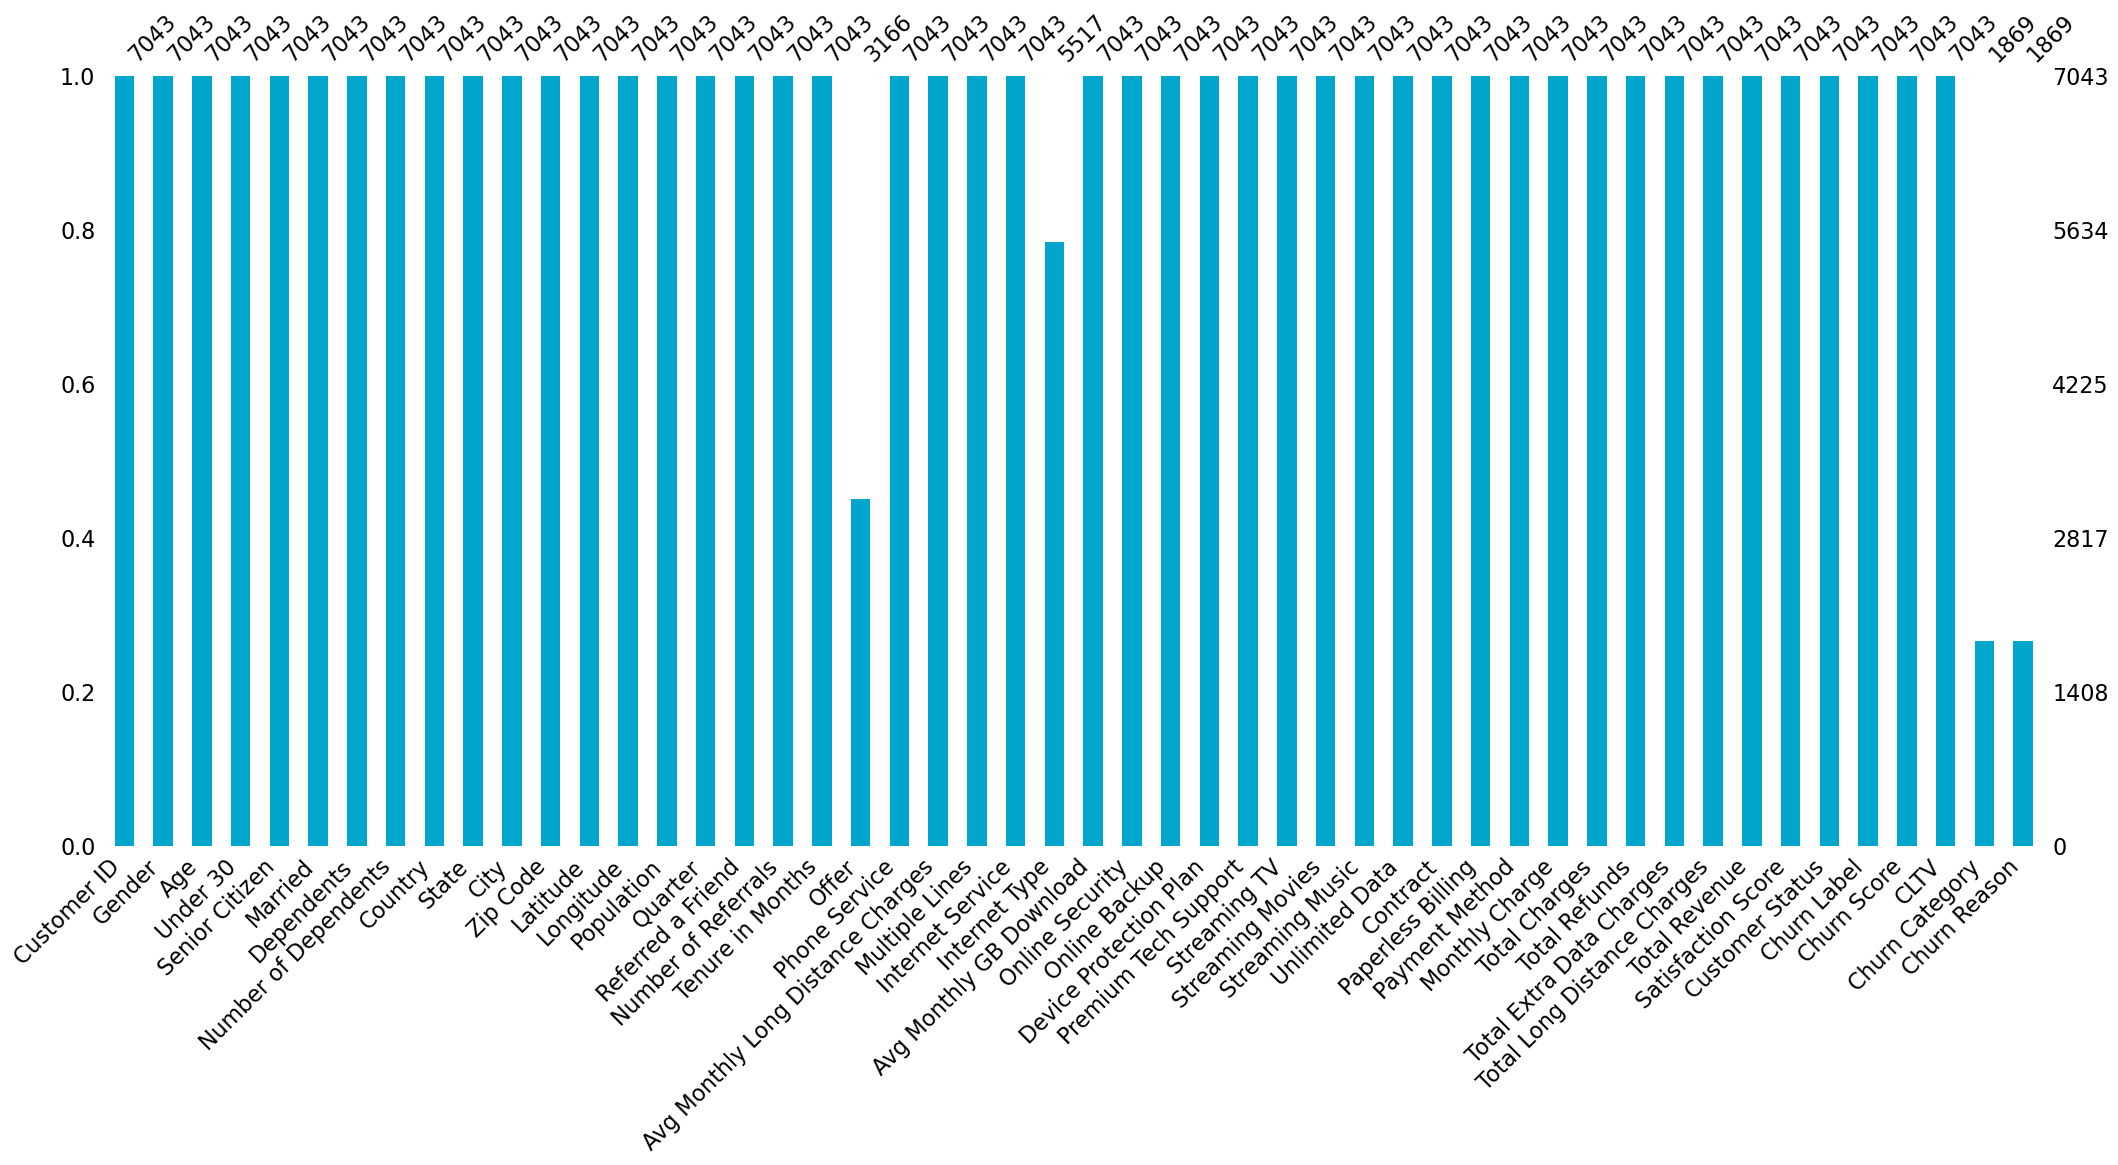

In [6]:
fig = msno.bar(df, color=(0, 0.65, 0.8))

<p>We can see that the following columns have the missing values:</p>
<ul>
    <li>Offer</li>
    <li>Internet Type</li>
    <li>Churn Category</li>
    <li>Churn Reason</li>
</ul>
Churn Category and Churn Reason both have equal number of missing value

In [7]:
tempdf =  df[df['Churn Label'] == 'No'][['Churn Label','Churn Category','Churn Reason']]
tempdf.rename(columns={"Churn Label": "No Churn"}, inplace=True)
df['Churn Category'].isnull().sum()

np.int64(5174)

<Axes: >

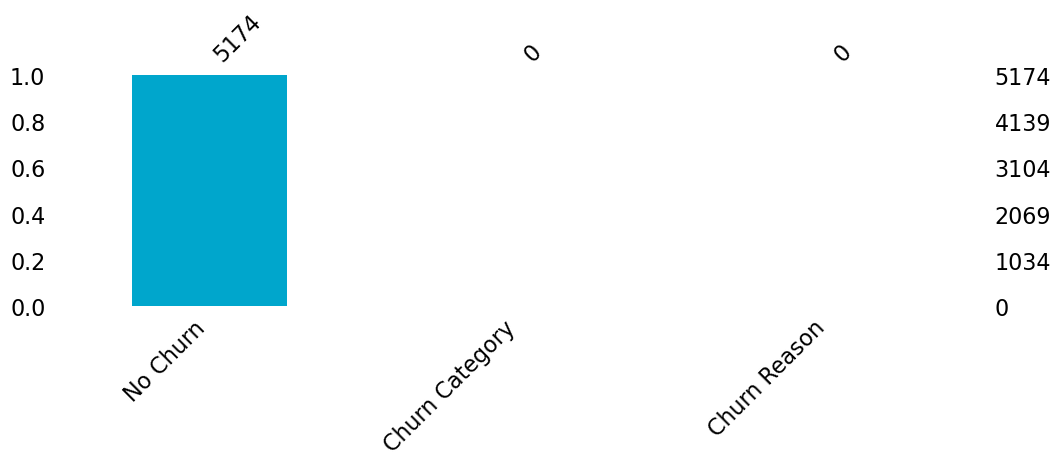

In [8]:
msno.bar(tempdf, color=(0, 0.65, 0.8),figsize=(12,3))

It is evident that the missing values in <b>Churn Category</b> and <b>Churn Reason</b> exist because the customer has not churned yet.<br>
We will replace missing values with a string like "No Churn" or "Not Applicable"

In [9]:
df['Churn Category'] = df['Churn Category'].fillna('No Churn')
df['Churn Reason'] = df['Churn Reason'].fillna('Not Applicable')

<div style="background: linear-gradient(135deg, #4F46E5 0%, #7C3AED 100%);margin-top: 10px; margin-bottom: 5px;padding: 5px 10px;border-radius: 12px; text-align: left; box-shadow: 0 10px 25px rgba(0, 0, 0, 0.1);">
        <h2 style="font-size: 1.8em; color: white; border-bottom: 2px solid #e5e7eb; padding-bottom: 10px; margin-bottom: 20px; display: flex; align-items: center; font-weight: 600;">
            <span style="font-size: 1.2em; margin-right: 12px;">3.</span>Handling Missing Values
        </h2>
    </div>

In [10]:
df['Offer'].value_counts()

Offer
Offer B    824
Offer E    805
Offer D    602
Offer A    520
Offer C    415
Name: count, dtype: int64

In [11]:
df['Offer'] = df['Offer'].fillna('No Offer')

### Handling missing values in Internet Type

In [12]:
df['Internet Type'].value_counts()

Internet Type
Fiber Optic    3035
DSL            1652
Cable           830
Name: count, dtype: int64

In [13]:
df['Internet Type'] = df['Internet Type'].fillna('No Internet')

<h4>We have handled all the missing values</h4>

<Axes: >

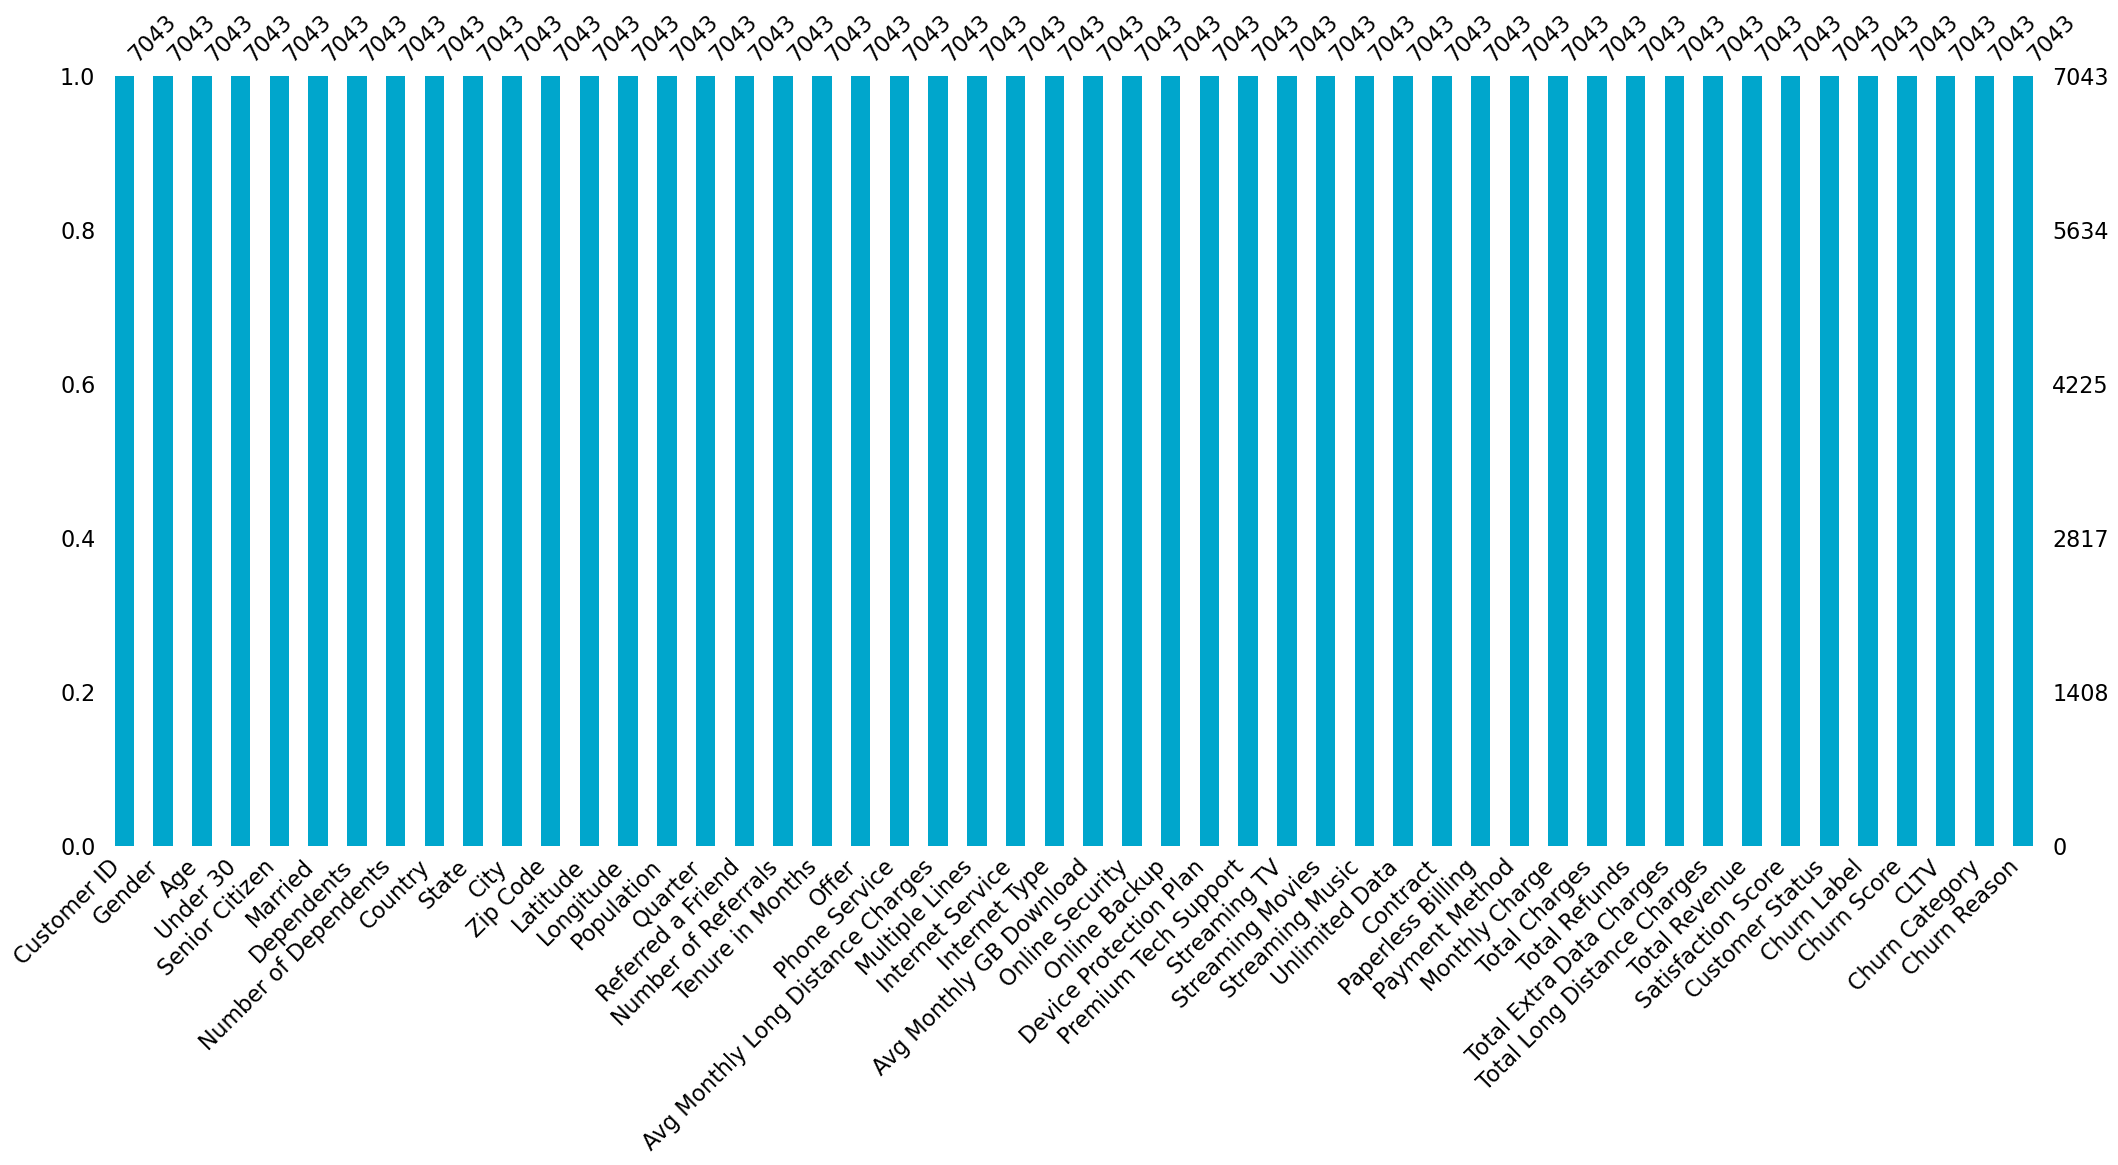

In [14]:
msno.bar(df, color=(0, 0.65, 0.8))

<div style="background: linear-gradient(135deg, #4F46E5 0%, #7C3AED 100%);margin-top: 10px; margin-bottom: 5px;padding: 5px 10px;border-radius: 12px; text-align: left; box-shadow: 0 10px 25px rgba(0, 0, 0, 0.1);">
        <h2 style="font-size: 1.8em; color: white; border-bottom: 2px solid #e5e7eb; padding-bottom: 10px; margin-bottom: 20px; display: flex; align-items: center; font-weight: 600;">
            <span style="font-size: 1.2em; margin-right: 12px;">4.</span>Helper Functions
        </h2>
    </div>

In [15]:
def plot_100_stacked_bar(dataframe: pd.DataFrame, categorical_col: str, target_col: str):
    """
    Generates and displays a 100% stacked bar chart to show the proportional
    distribution of a target column across different categories of another column.

    This is the best way to visualize churn RATE for different segments, as it
    normalizes the data to show percentages rather than absolute counts.

    Args:
        dataframe (pd.DataFrame): The pandas DataFrame containing the data.
        categorical_col (str): The name of the categorical column for the x-axis
                               (e.g., 'Number of Dependents').
        target_col (str): The name of the categorical target column used for stacking
                          (e.g., 'Churn Label').

    Returns:
        None: The function displays the plot directly.
    """
    # --- Data Preparation ---
    # Create a cross-tabulation of the two columns and normalize it by index (rows)
    # This calculates the proportion of each target category within each categorical group
    props = pd.crosstab(dataframe[categorical_col], dataframe[target_col], normalize='index')

    # Reorder columns to ensure 'Yes' (or the churn indicator) is plotted first for consistency
    # This is optional but good for visual storytelling. Let's find the positive churn label.
    churn_yes_label = dataframe[dataframe[target_col] == 'Yes'][target_col].iloc[0]
    churn_no_label = dataframe[dataframe[target_col] == 'No'][target_col].iloc[0]
    if churn_yes_label in props.columns:
        props = props[[churn_yes_label, churn_no_label]]

    # --- Plotting ---
    plt.style.use('seaborn-v0_8-whitegrid')
    ax = props.plot(
        kind='bar',
        stacked=True,
        figsize=(12, 7),
        color=sns.color_palette("viridis", len(props.columns))
    )

    # --- Formatting ---
    # Format the y-axis to show percentages
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0))

    # Add percentage labels inside the bars
    for container in ax.containers:
        # Custom formatting for labels: only show if value > 0 to avoid clutter
        labels = [f'{val:.1%}' if val > 0 else '' for val in container.datavalues]
        ax.bar_label(container, labels=labels, label_type='center', color='white', weight='bold')

    # Final plot customizations
    plt.title(f'Proportion of {target_col} by {categorical_col}', fontsize=16)
    plt.xlabel(categorical_col, fontsize=12)
    plt.ylabel(f'Percentage of Customers', fontsize=12)
    plt.xticks(rotation=0)
    # Move legend outside of the plot
    plt.legend(title=target_col, bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

In [16]:
def plot_correlation_heatmap(df, columns, title="Correlation Matrix of Key Features"):
    """
    Calculates and plots a correlation matrix heatmap for specified columns in a DataFrame.

    This function is designed to visually inspect multicollinearity between numerical features.
    High correlation is indicated by colors closer to red (positive) or dark blue (negative).

    Args:
        df (pd.DataFrame): The pandas DataFrame containing the data.
        columns (list): A list of column names for which to calculate the correlation.
        title (str): The title of the plot.
    """
    # Ensure all columns exist in the DataFrame to avoid errors
    valid_columns = [col for col in columns if col in df.columns]
    if not valid_columns:
        print("Error: None of the specified columns were found in the DataFrame.")
        return

    # Calculate the correlation matrix for the specified columns
    correlation_matrix = df[valid_columns].corr()

    # Set up the matplotlib figure
    plt.figure(figsize=(12, 10))

    # Generate a heatmap with a clear color map, annotations, and formatting
    sns.heatmap(
        correlation_matrix,
        annot=True,          # Display the correlation values on the heatmap
        fmt=".2f",           # Format the numbers to two decimal places
        cmap='coolwarm',     # Use a diverging colormap (red for positive, blue for negative)
        linewidths=.5,       # Add lines between cells
        linecolor='lightgray'
    )

    # Add a title and adjust layout
    plt.title(title, fontsize=16, pad=20)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

In [17]:
def plot_overlaid_distribution(dataframe: pd.DataFrame, numerical_col: str, target_col: str, plot_type: str = 'hist'):
    """
    Generates and displays an overlaid plot (histogram or KDE) to compare the distribution
    of a numerical column across different categories of a target column.

    This is particularly useful in EDA for binary classification problems (like churn) to see
    how a feature's distribution differs between the positive and negative classes.

    Args:
        dataframe (pd.DataFrame): The pandas DataFrame containing the data.
        numerical_col (str): The name of the numerical column to be plotted on the x-axis.
        target_col (str): The name of the categorical target column used for grouping (e.g., 'Churn Label').
        plot_type (str, optional): The type of plot to generate. Accepts 'hist' for histogram
                                   or 'kde' for Kernel Density Estimate plot. Defaults to 'hist'.

    Returns:
        None: The function displays the plot directly.
    """
    # Validate plot_type input
    if plot_type not in ['hist', 'kde']:
        print("Error: plot_type must be either 'hist' or 'kde'.")
        return

    # Set up the plot aesthetics
    plt.style.use('seaborn-v0_8-whitegrid')
    plt.figure(figsize=(10, 6))

    # Separate the data for the two main categories in the target column for clarity in the legend
    # Assumes a binary target, but will work for more. We'll find the top two value counts.
    #top_categories = dataframe[target_col].value_counts().nlargest(2).index
    
    # val1 = top_categories[0]
    # val2 = top_categories[1]
    
    # Create the plot using seaborn
    if plot_type == 'hist':
        # Using histplot with 'hue' for automatic separation and coloring
        # 'kde=True' adds a density line over the histogram bars
        # 'common_norm=False' ensures each group's histogram is normalized independently
        sns.histplot(data=dataframe, x=numerical_col, hue=target_col, kde=True,
                     palette='viridis', alpha=0.6, multiple='layer', common_norm=False)
        plot_title = f'Overlaid Histogram of {numerical_col} by {target_col}'
    else: # plot_type == 'kde'
        # Using kdeplot, which is great for showing the shape of the distributions
        sns.kdeplot(data=dataframe, x=numerical_col, hue=target_col,
                    fill=True, palette='viridis', alpha=0.5, common_norm=False)
        plot_title = f'Overlaid KDE Plot of {numerical_col} by {target_col}'

    # Final plot customizations
    plt.title(plot_title, fontsize=16)
    plt.xlabel(numerical_col, fontsize=12)
    plt.ylabel('Density' if plot_type == 'kde' else 'Count', fontsize=12)
    #plt.legend(title=target_col, labels=[val2, val1]) # Manually set labels for clarity if needed
    plt.tight_layout()
    plt.show()

In [18]:
def plot_countplot(dataframe: pd.DataFrame, categorical_col: str, target_col: str):
    """
    Generates and displays a count plot for a categorical column, broken down by a target
    column (hue).

    This is ideal for visualizing the absolute counts of different outcomes (e.g., Churn vs. No Churn)
    for each category in a feature (e.g., Contract Type, Payment Method).

    Args:
        dataframe (pd.DataFrame): The pandas DataFrame containing the data.
        categorical_col (str): The name of the categorical column for the x-axis.
        target_col (str): The name of the categorical target column used for the hue.

    Returns:
        None: The function displays the plot directly.
    """
    # Set up the plot aesthetics
    plt.style.use('seaborn-v0_8-whitegrid')
    plt.figure(figsize=(12, 7))

    # Create the plot using seaborn's countplot
    ax = sns.countplot(data=dataframe, x=categorical_col, hue=target_col, palette='viridis')

    # Add count labels on top of each bar for clarity
    for container in ax.containers:
        ax.bar_label(container, fmt='{:,.0f}', label_type='edge', padding=3)

    # Final plot customizations
    plt.title(f'Count of Customers by {categorical_col} and {target_col}', fontsize=16)
    plt.xlabel(categorical_col, fontsize=12)
    plt.ylabel('Number of Customers', fontsize=12)
    # Rotate x-axis labels if they are long to prevent overlap
    plt.xticks(rotation=45, ha='right')
    plt.legend(title=target_col)
    plt.tight_layout()
    plt.show()

<div style="background: linear-gradient(135deg, #4F46E5 0%, #7C3AED 100%);margin-top: 10px; margin-bottom: 5px;padding: 5px 10px;border-radius: 12px; text-align: left; box-shadow: 0 10px 25px rgba(0, 0, 0, 0.1);">
        <h2 style="font-size: 1.8em; color: white; border-bottom: 2px solid #e5e7eb; padding-bottom: 10px; margin-bottom: 20px; display: flex; align-items: center; font-weight: 600;">
            <span style="font-size: 1.2em; margin-right: 12px;">5.</span>Exploratory Data Analysis (EDA)
        </h2>
    </div>

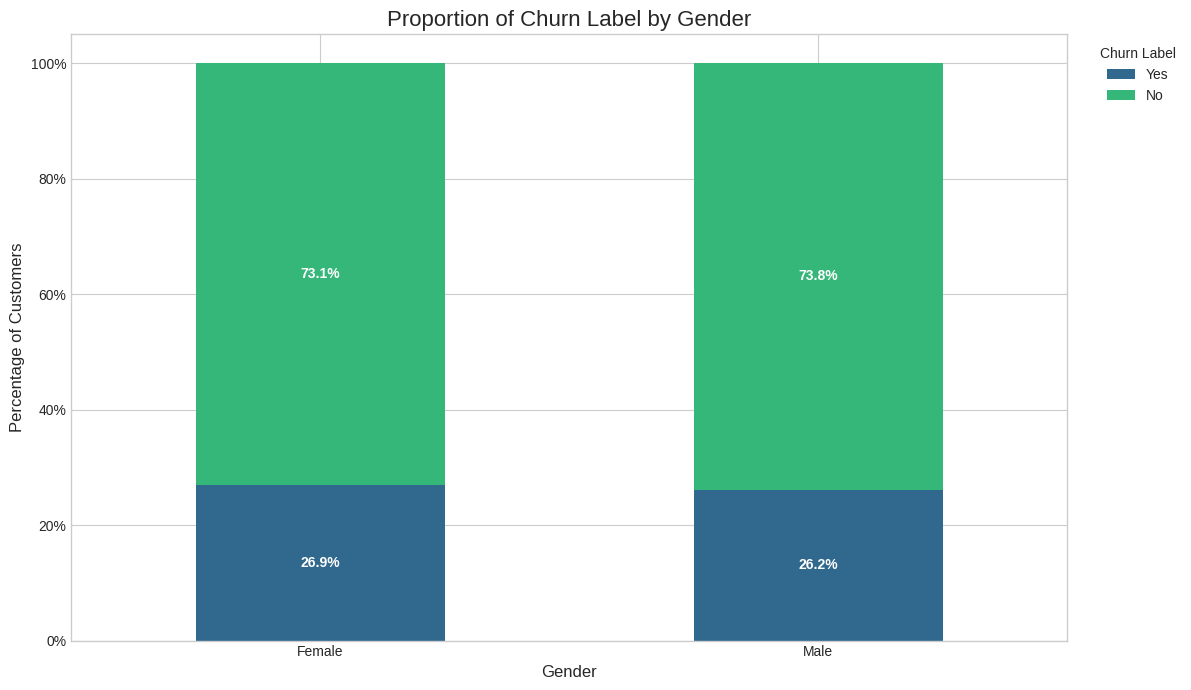

In [19]:
plot_100_stacked_bar(df,"Gender","Churn Label")

Gender is not a strong predictor of churn

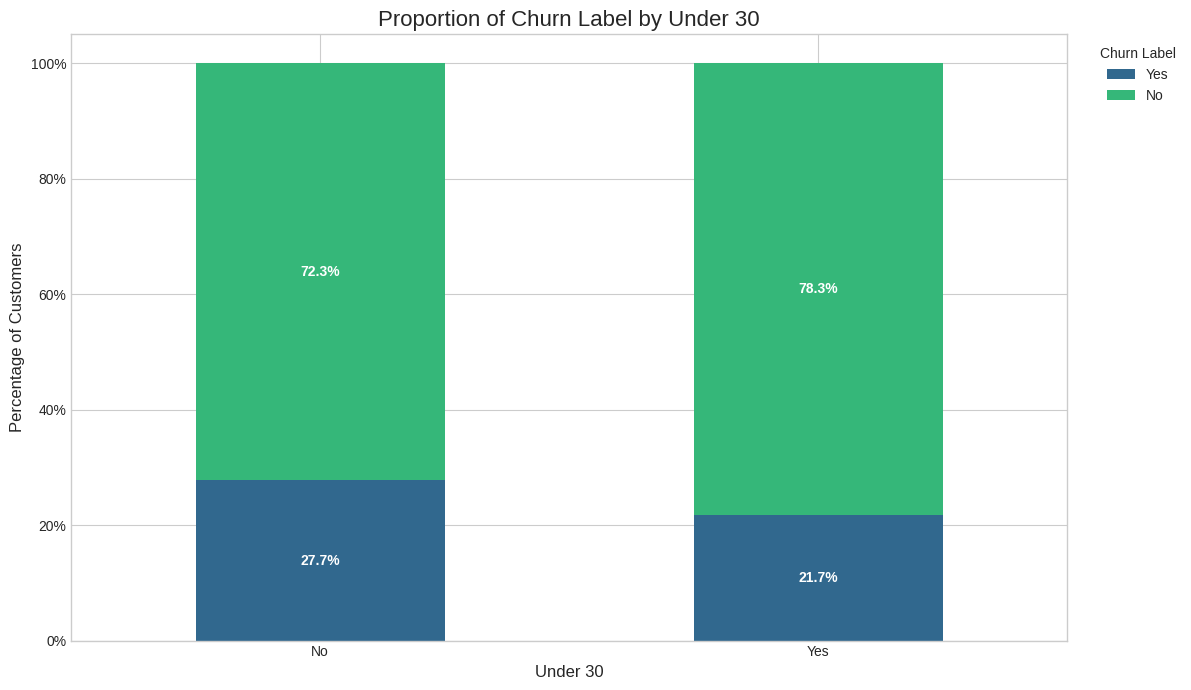

In [20]:
plot_100_stacked_bar(df,"Under 30","Churn Label") 

<ul>
    <li>The majority of customers under 30 do not churn (≈ 75–78%).</li>
    <li>Only about 22–25% churn in this age group.</li>
</ul>

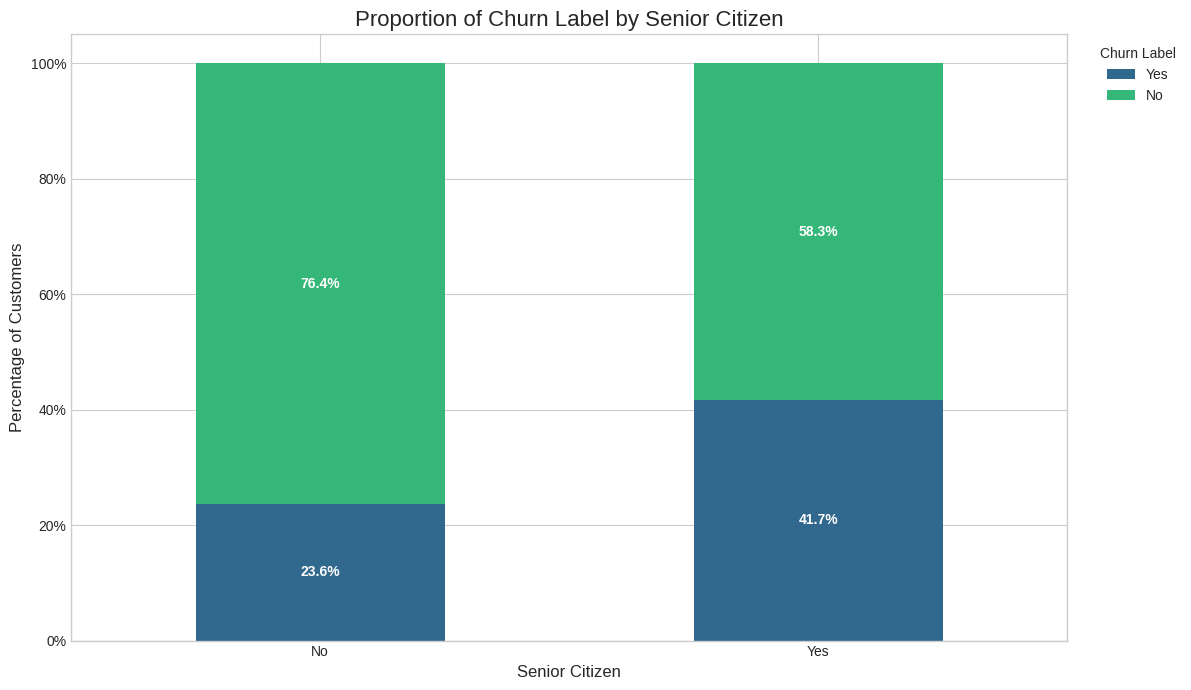

In [21]:
plot_100_stacked_bar(df,"Senior Citizen","Churn Label") 

<ul>
    <li>Around 40–42% of senior citizens churn, compared to only about 22–25% of customers under 30.</li>
    <li>Seniors are therefore a high-risk group, with churn rates nearly double that of younger customers.</li>
    <li>Therefore Senior Citizen is a strong predictor of churn.</li>
</ul>

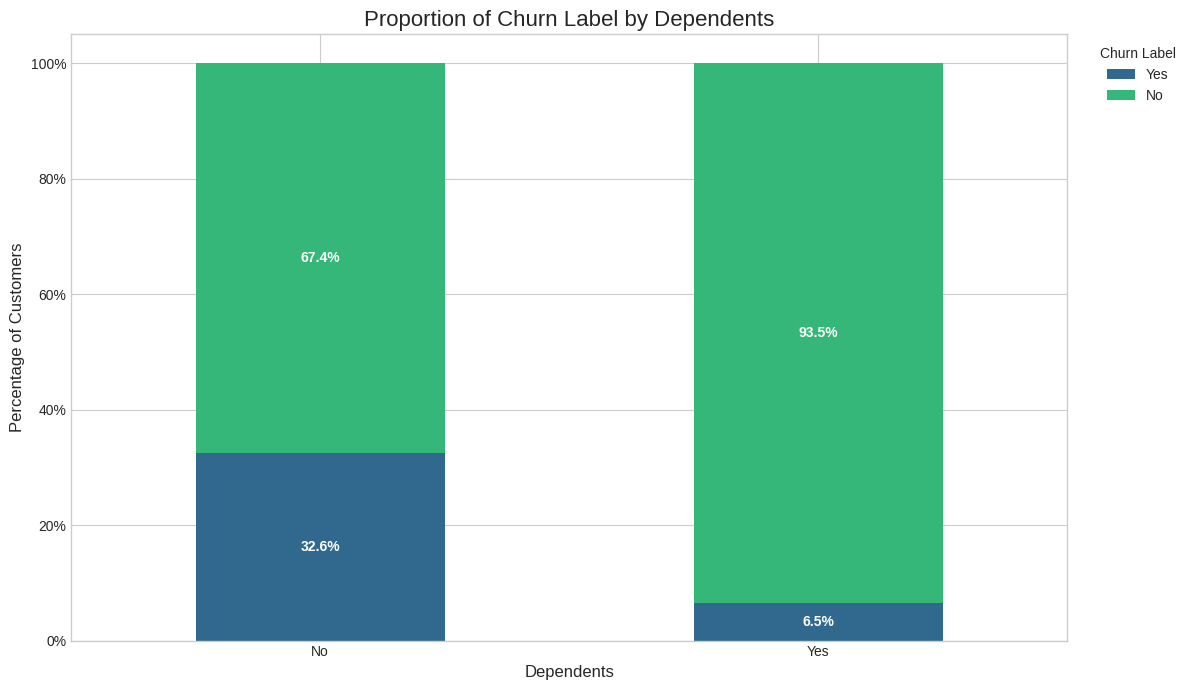

In [22]:
plot_100_stacked_bar(df,"Dependents","Churn Label")

Based on the 100% stacked bar chart, customers with dependents are significantly less likely to churn compared to customers without dependents. The chart shows that the vast majority of customers who have dependents did not churn ('No'), while a much smaller percentage of customers without dependents also did not churn. This suggests that having dependents is a strong indicator of customer retention.

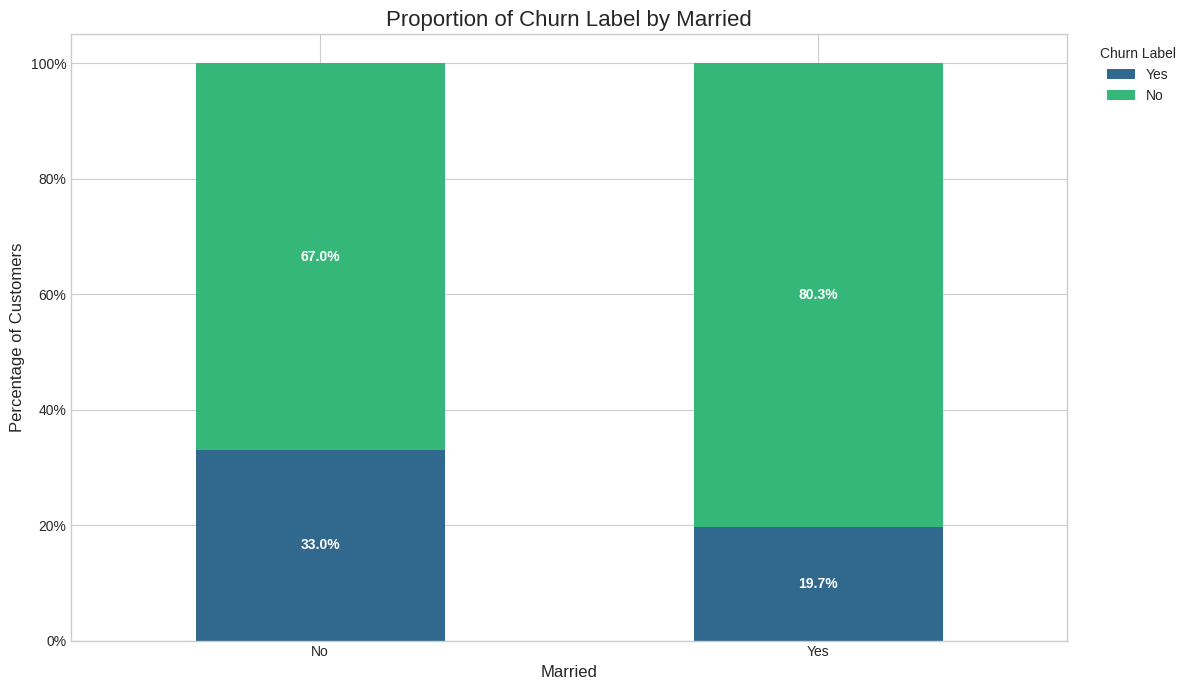

In [23]:
plot_100_stacked_bar(df,"Married","Churn Label") 

<ol>
<li><b>Lower Churn for Married Customers:</b> Customers who are married have a significantly lower churn rate compared to those who are not.</li>

<li><b>Higher Churn for Unmarried Customers:</b> The churn rate for unmarried customers is notably higher, with approximately 35% of them churning.</li>

<li><b>Higher Retention for Married Customers:</b> Conversely, the retention rate for married customers is higher, with around 80% of them not churning.</li>
</ol>

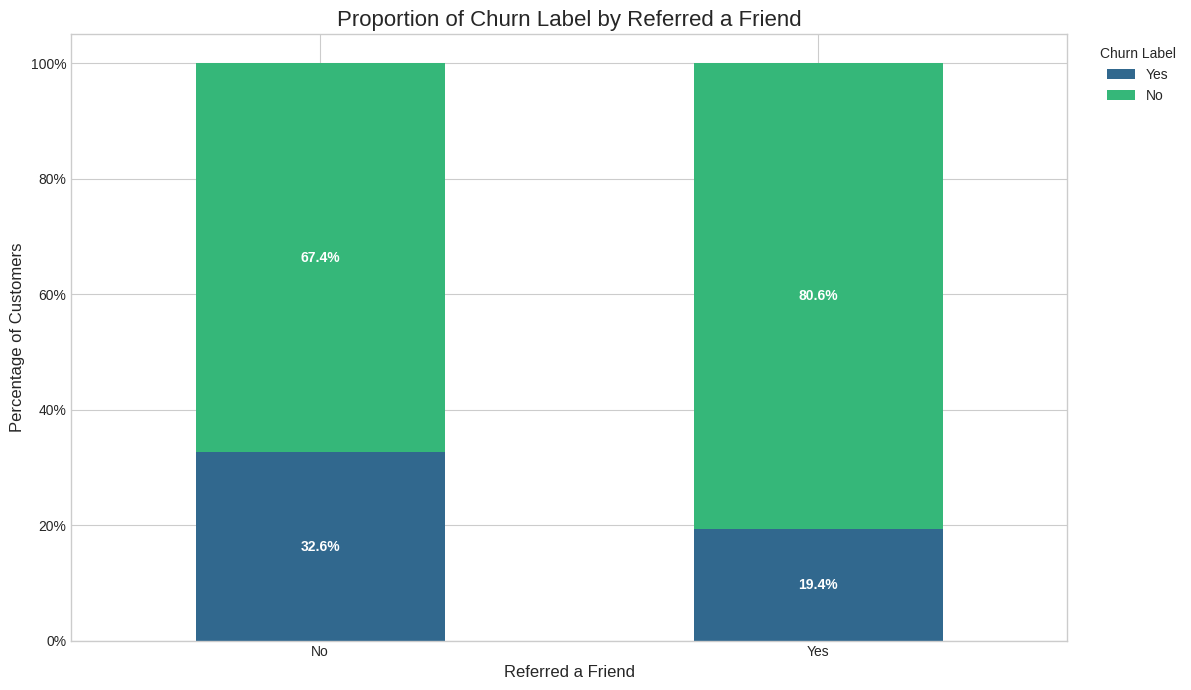

In [24]:
plot_100_stacked_bar(df,"Referred a Friend","Churn Label") 

<ul>
    <li>Customers who have referred a friend are significantly less likely to churn than those who haven't.</li>
    <li>The churn rate for customers who did not refer a friend is approximately 33%.</li>
    <li>Conversely, the churn rate for customers who did refer a friend is much lower, at approximately 20%.</li>
</ul>

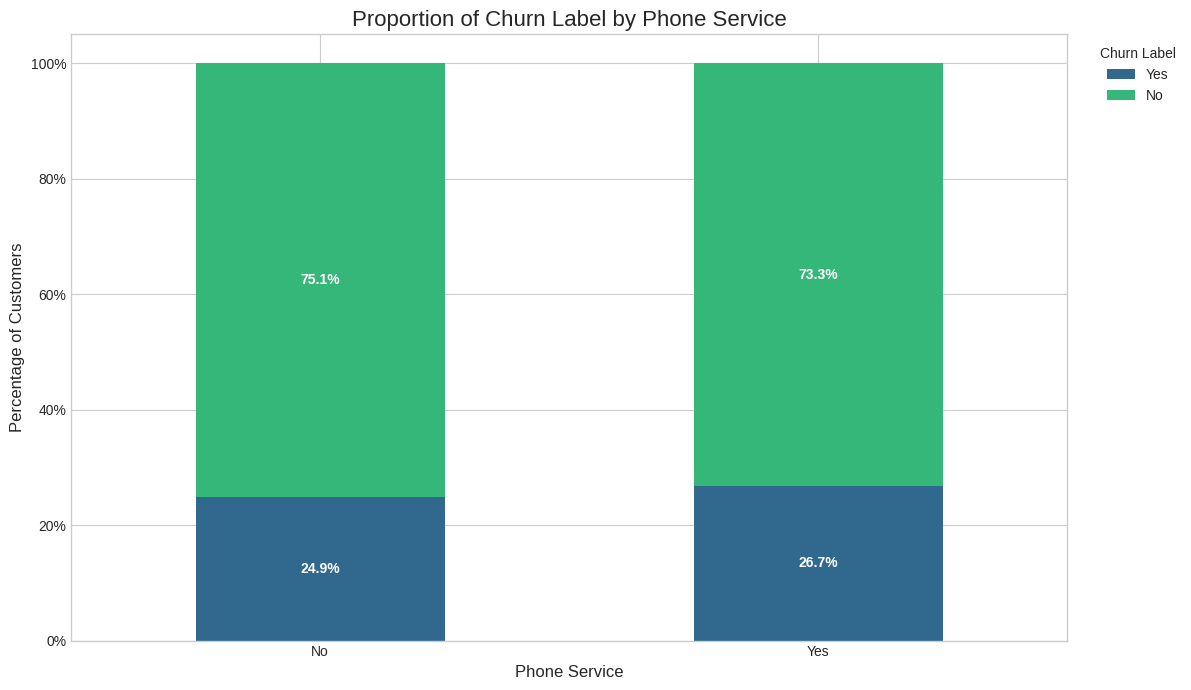

In [25]:
plot_100_stacked_bar(df,"Phone Service","Churn Label")

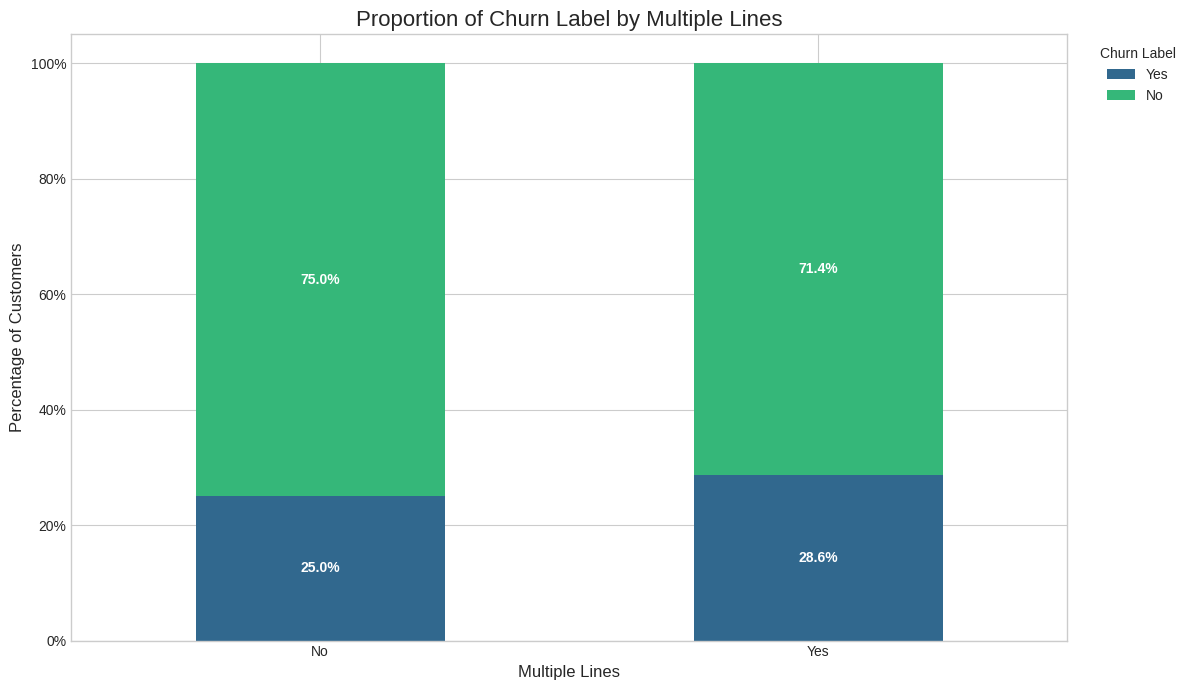

In [26]:
plot_100_stacked_bar(df,"Multiple Lines","Churn Label")

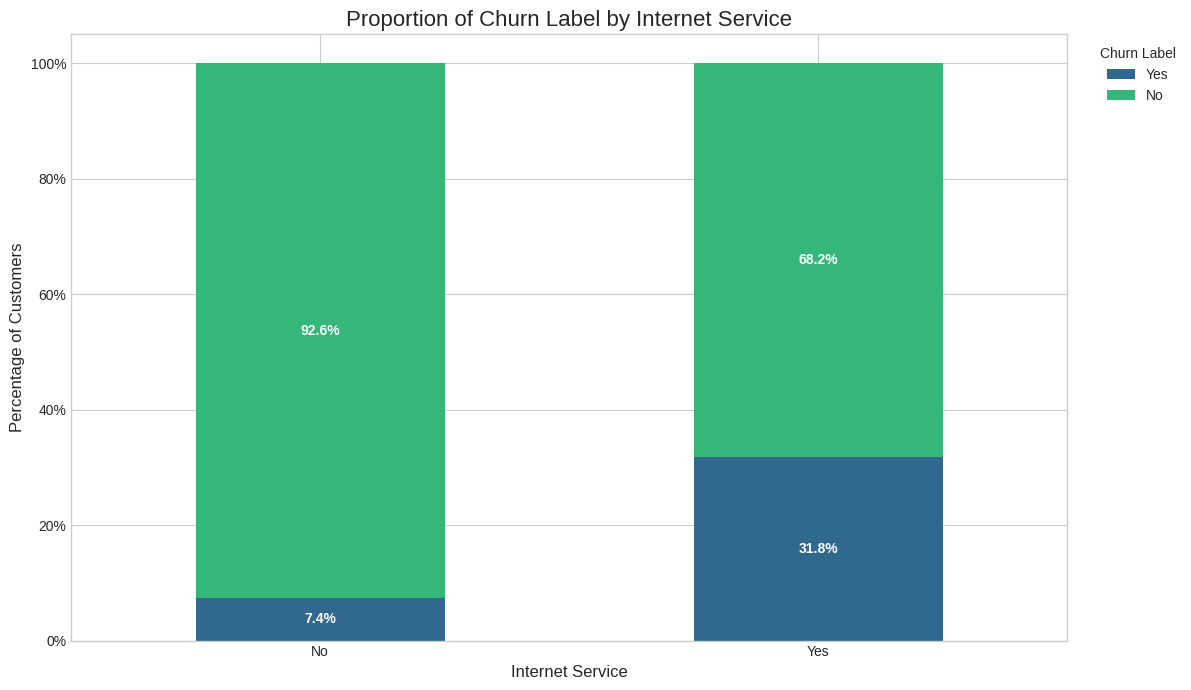

In [27]:
plot_100_stacked_bar(df,"Internet Service","Churn Label")

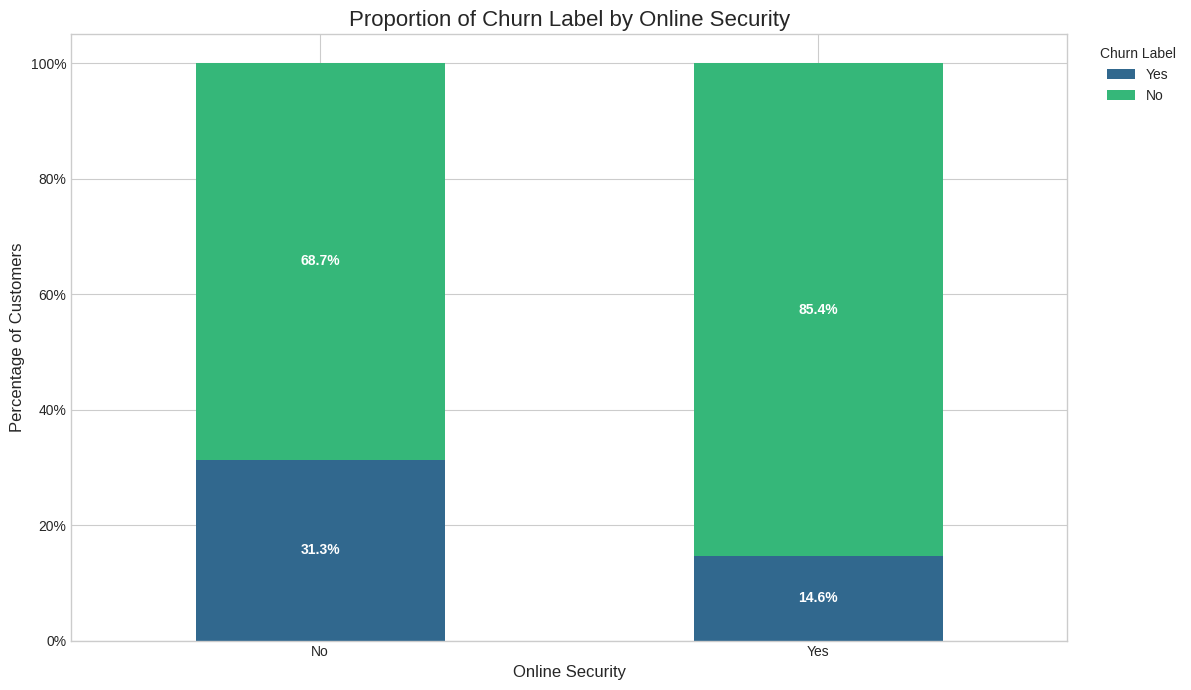

In [28]:
plot_100_stacked_bar(df,"Online Security","Churn Label")

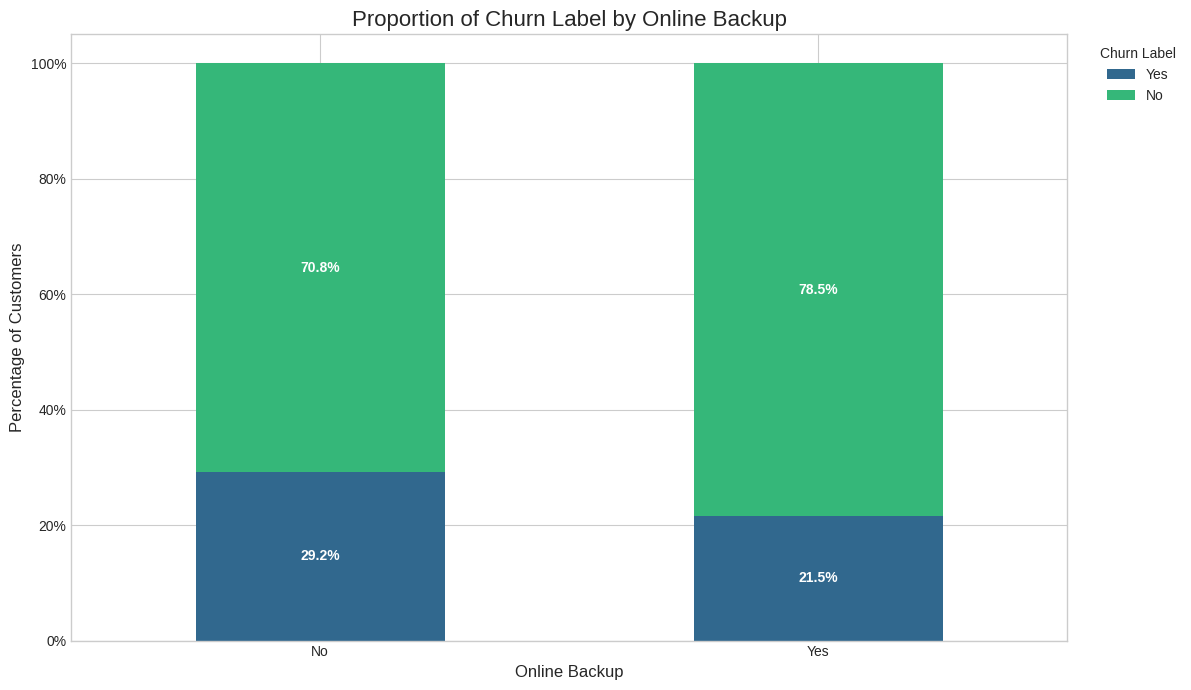

In [29]:
plot_100_stacked_bar(df,"Online Backup","Churn Label")

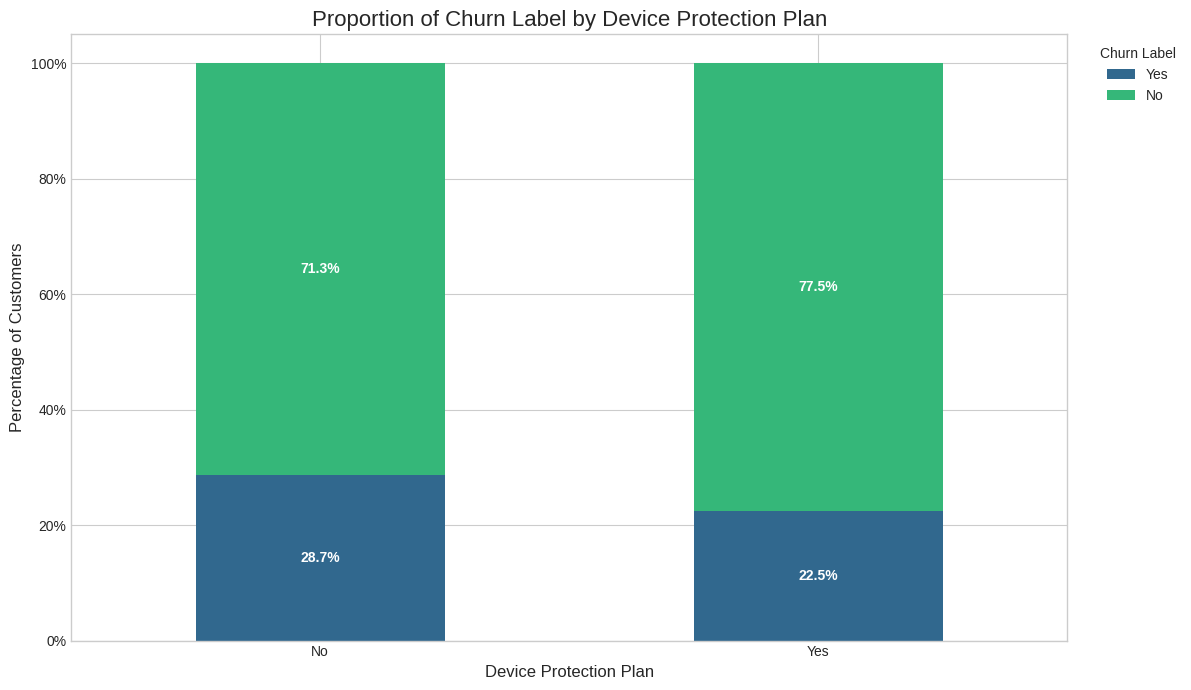

In [30]:
plot_100_stacked_bar(df,"Device Protection Plan","Churn Label")

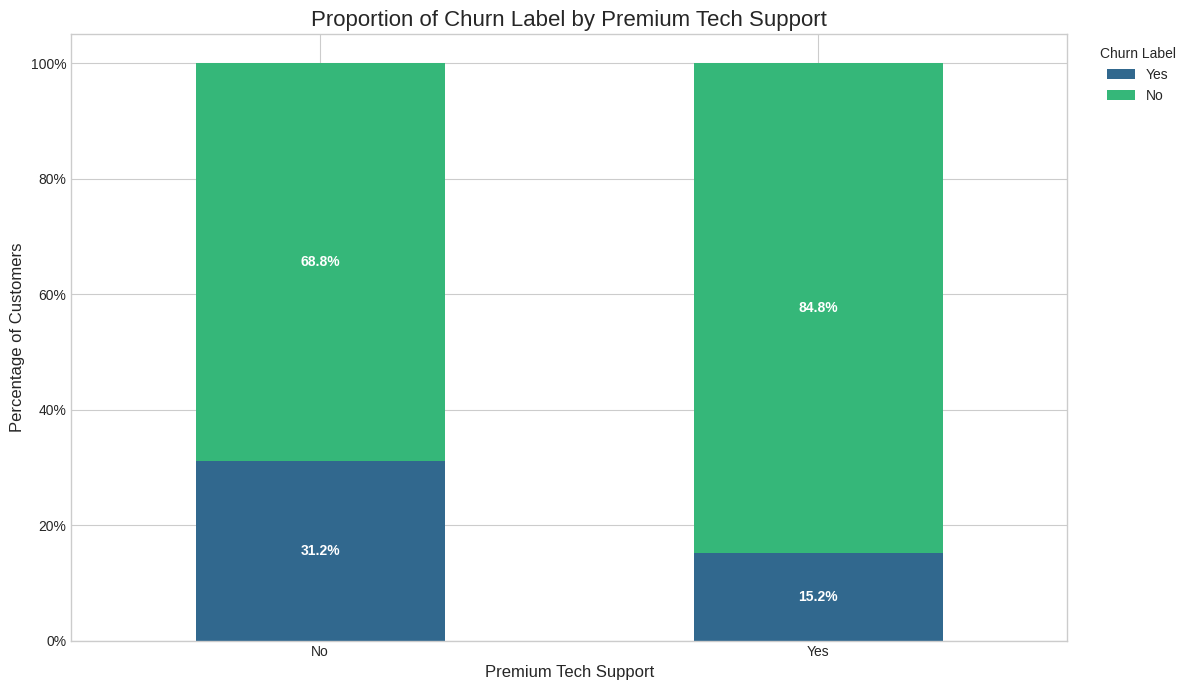

In [31]:
plot_100_stacked_bar(df,"Premium Tech Support","Churn Label")

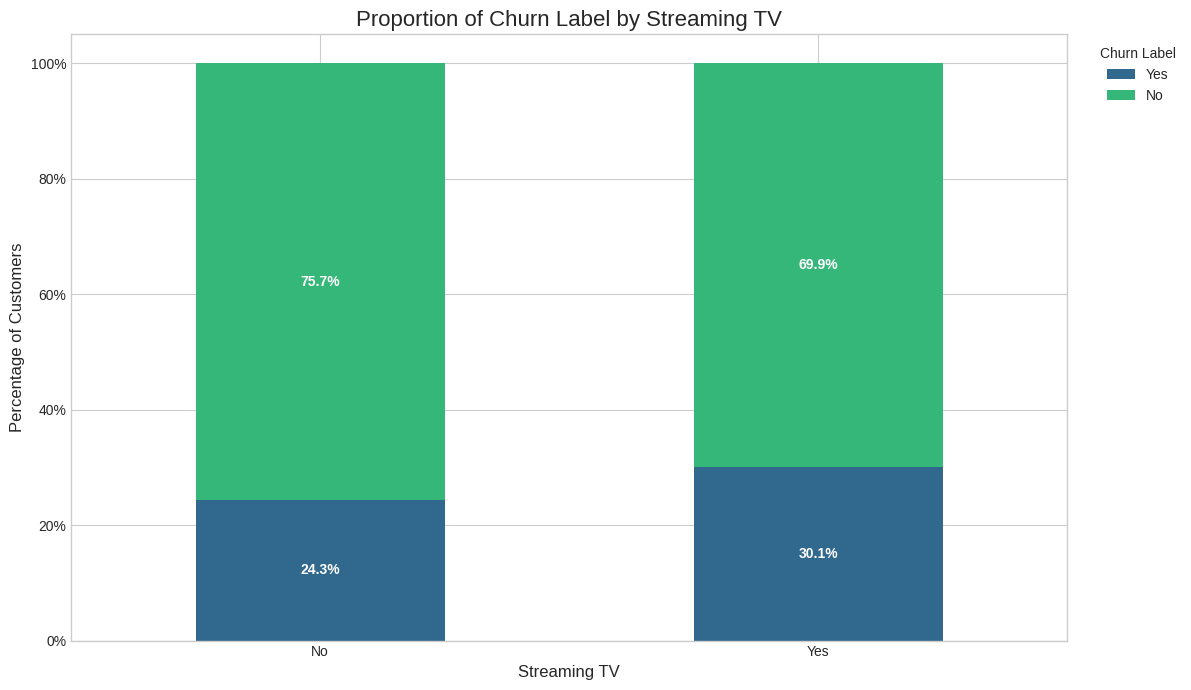

In [32]:
plot_100_stacked_bar(df,"Streaming TV","Churn Label")

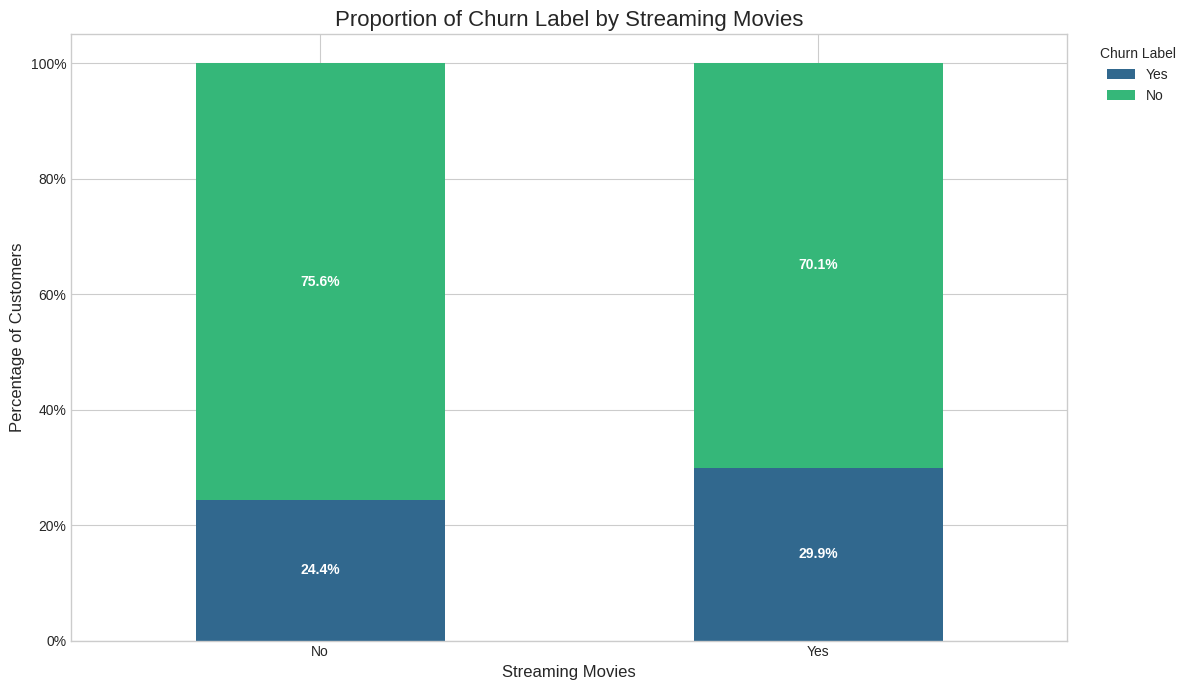

In [33]:
plot_100_stacked_bar(df,"Streaming Movies","Churn Label")

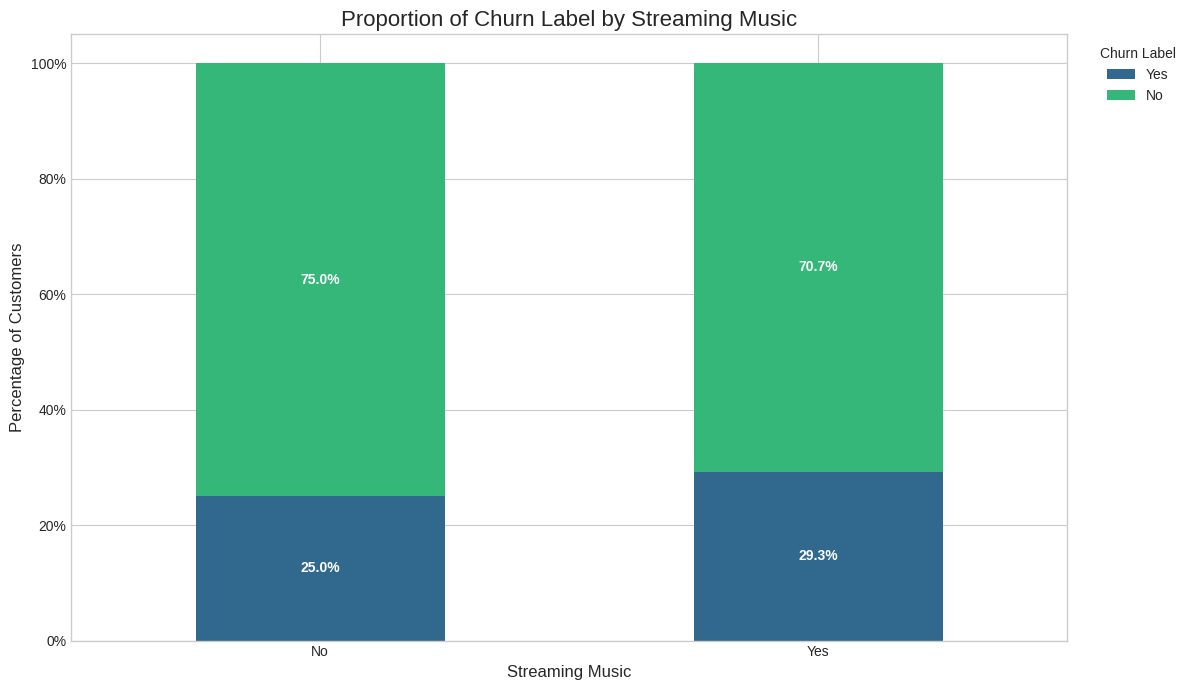

In [34]:
plot_100_stacked_bar(df,"Streaming Music","Churn Label")

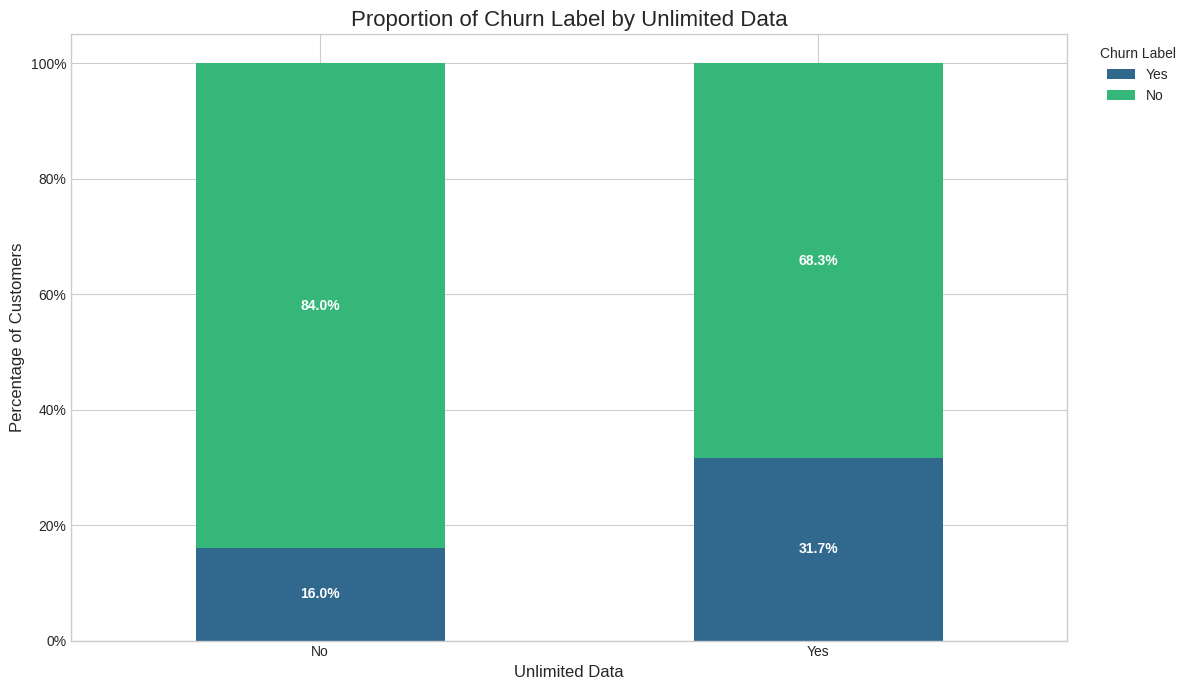

In [35]:
plot_100_stacked_bar(df,"Unlimited Data","Churn Label")

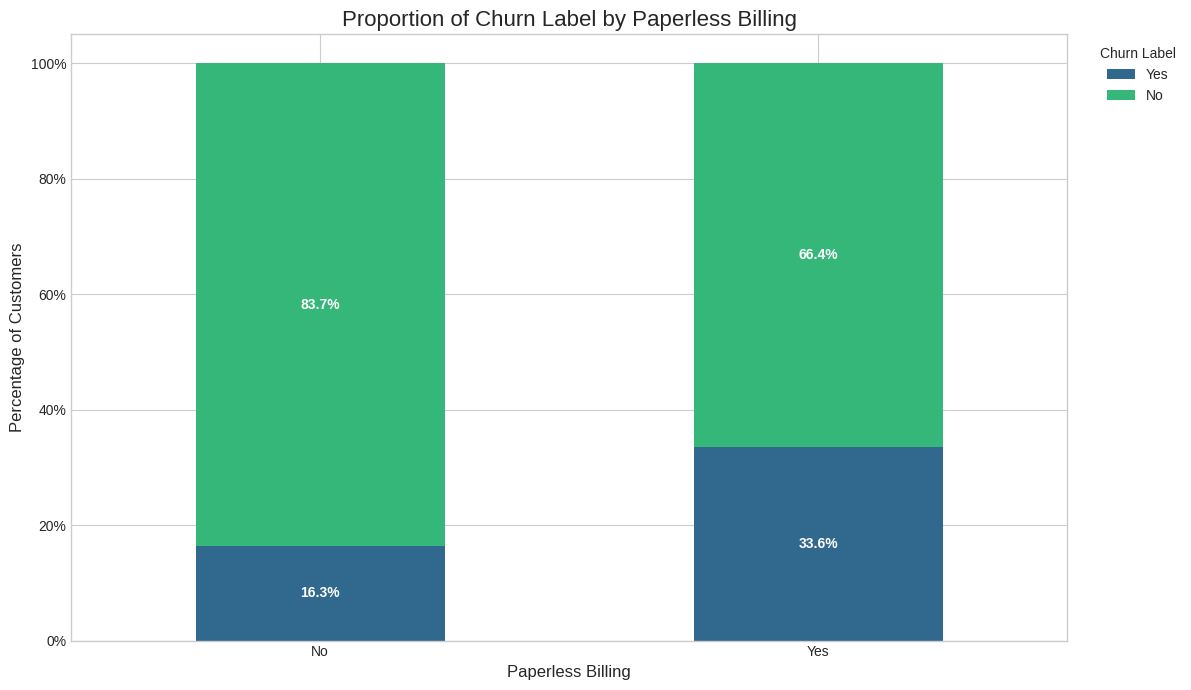

In [36]:
plot_100_stacked_bar(df,"Paperless Billing","Churn Label")

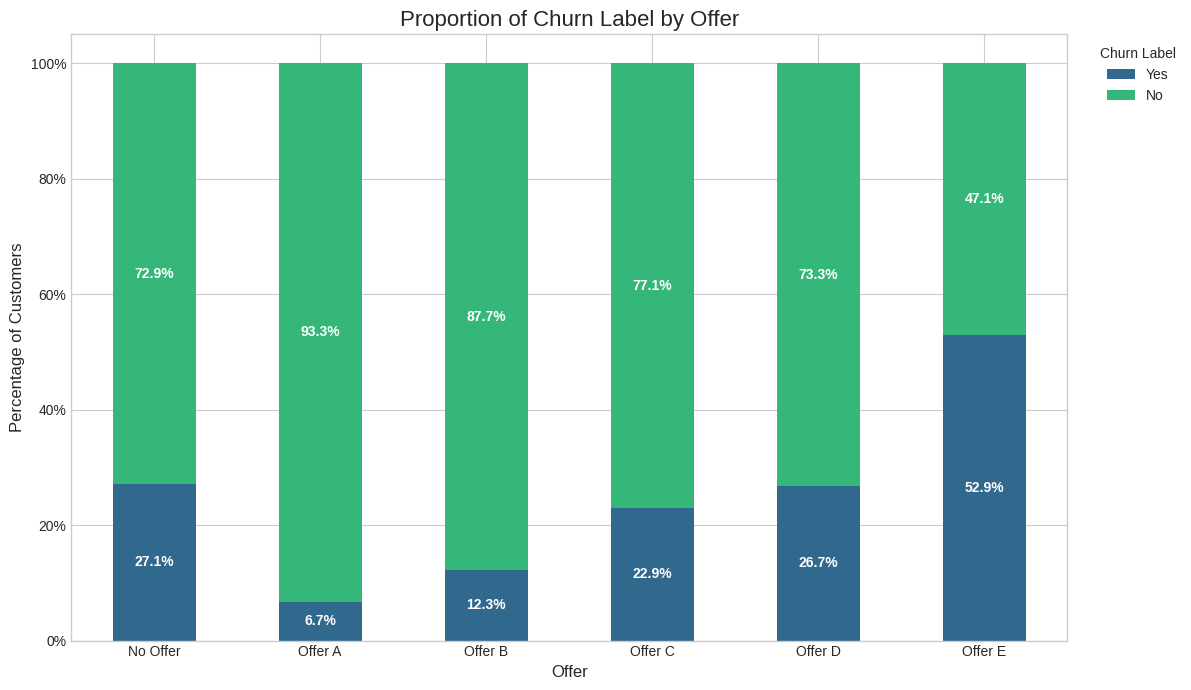

In [37]:
plot_100_stacked_bar(df,"Offer","Churn Label")

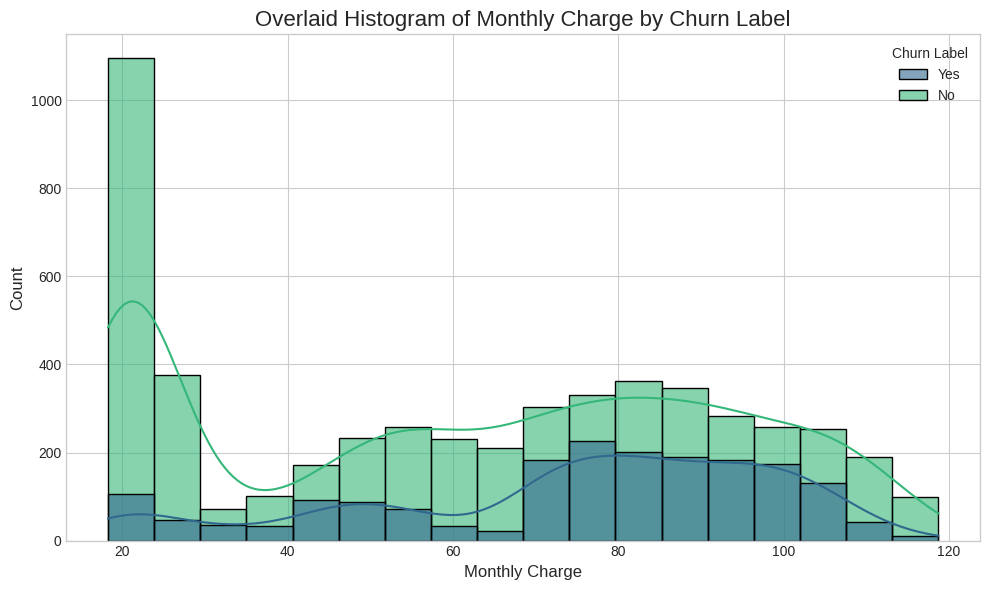

In [38]:
plot_overlaid_distribution(df, 'Monthly Charge', 'Churn Label', plot_type='hist')

<ul>
    <Li>The business is facing two distinct churn problems: A high-volume churn problem with low-value customers, and a high-risk, high-damage churn problem with premium customers.</Li>
    <li>Once a customer's monthly charge exceeds roughly $45, they enter a high-risk category, and their probability of churning becomes greater than their probability of staying.</li>
</ul>

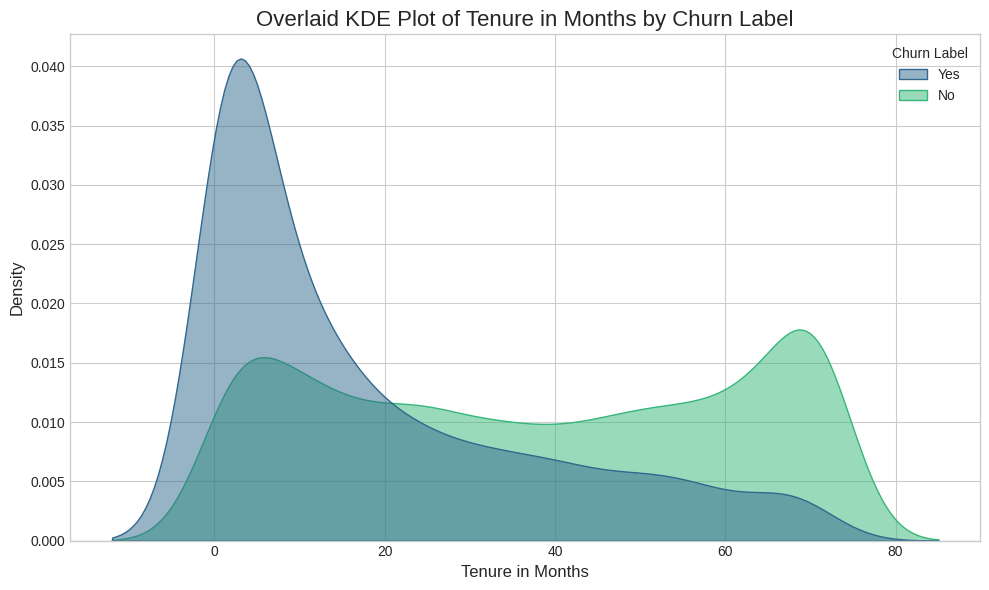

In [39]:
plot_overlaid_distribution(df, 'Tenure in Months', 'Churn Label', plot_type='kde')

<h3>A "U-Shaped" or Bimodal Distribution</h3>
<h4>The Left Peak, approx. 0-15 months</h4>
<p>A very large portion of your non-churning customers are relatively new.These are all the new people who have signed up and haven't left yet.</p>
<h4>The Right Peak, approx. 65-72 months</h4>
<p>An even larger and more concentrated group of your loyal customers have extremely long tenures. The strength of this peak indicates that if a customer makes it past the initial years, they become very likely to stay for the long haul.</p>

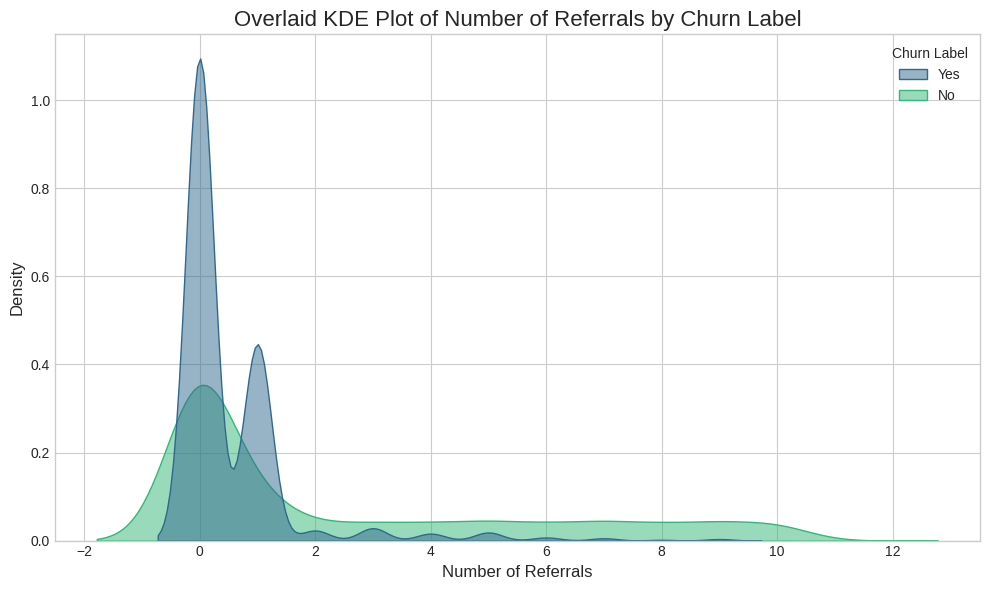

In [40]:
plot_overlaid_distribution(df, 'Number of Referrals', 'Churn Label', plot_type='kde')

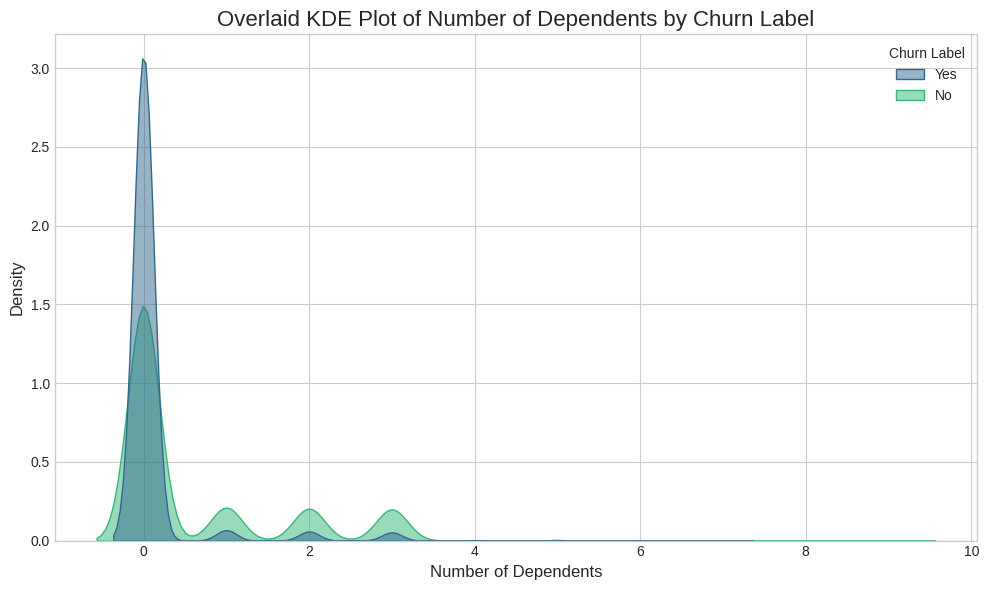

In [41]:
plot_overlaid_distribution(df, 'Number of Dependents', 'Churn Label', plot_type='kde')

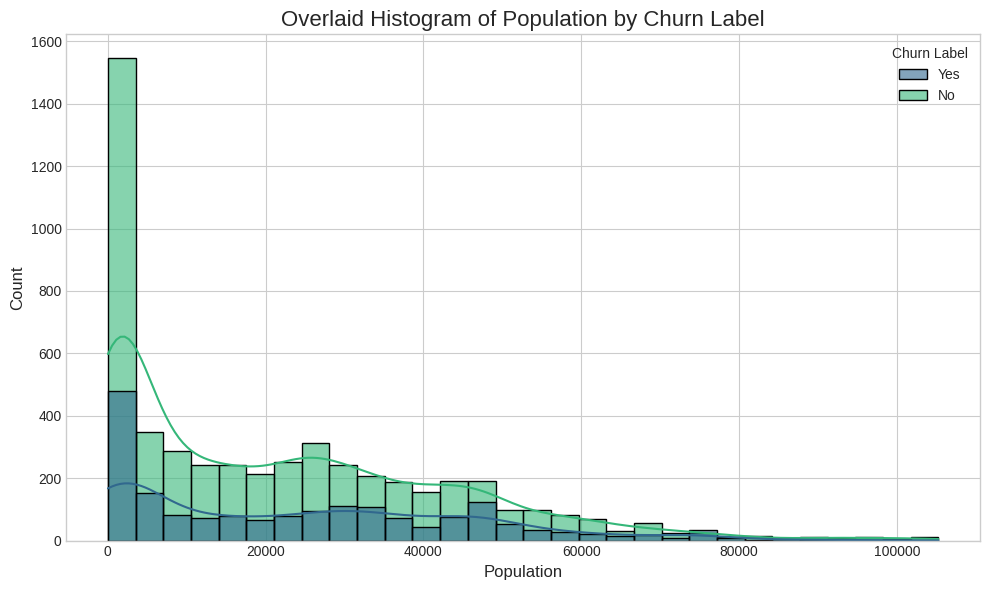

In [42]:
plot_overlaid_distribution(df, 'Population', 'Churn Label', plot_type='hist')

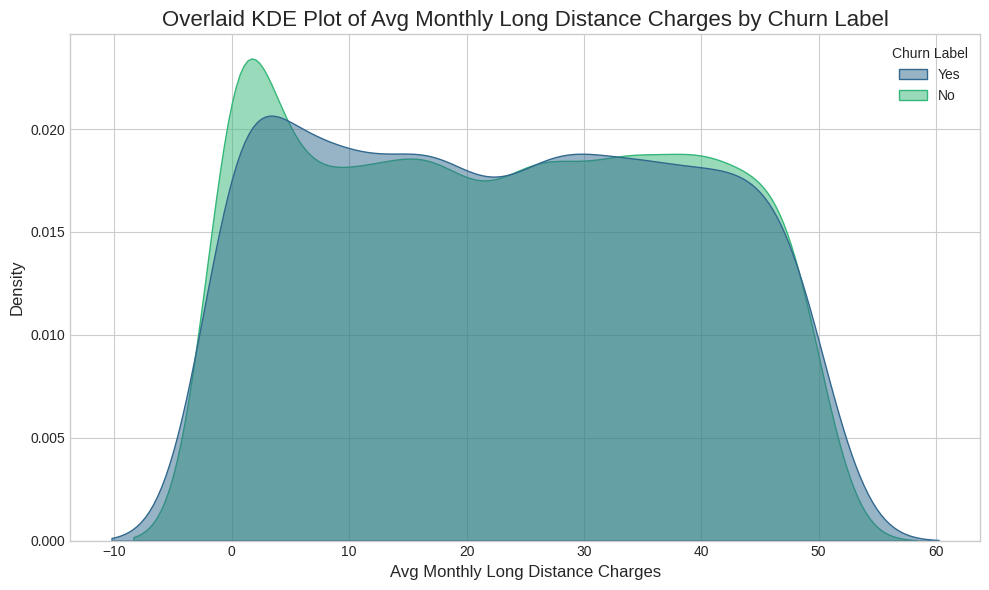

In [43]:
plot_overlaid_distribution(df, 'Avg Monthly Long Distance Charges', 'Churn Label', plot_type='kde')

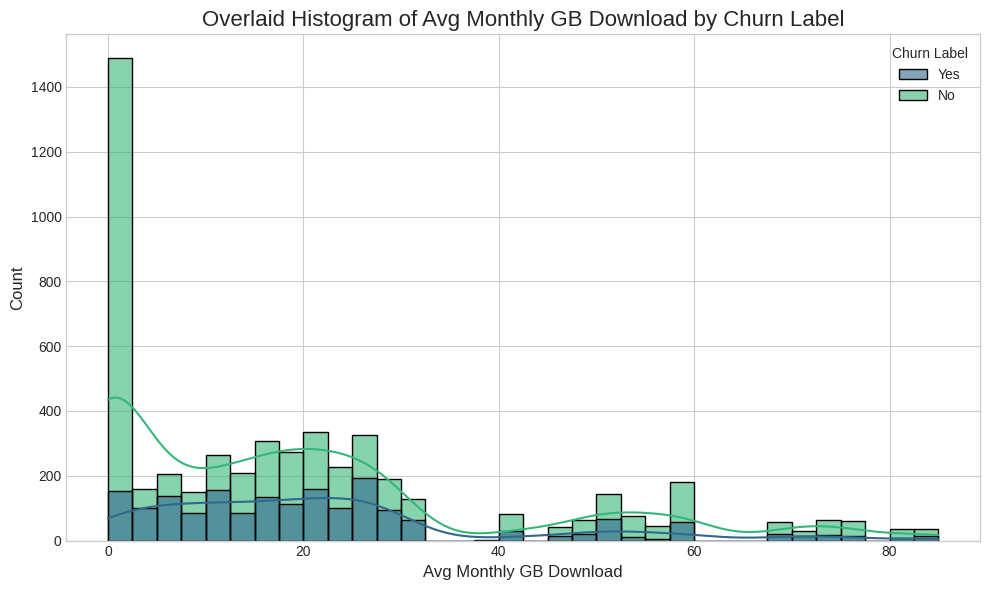

In [44]:
plot_overlaid_distribution(df, 'Avg Monthly GB Download', 'Churn Label', plot_type='hist')

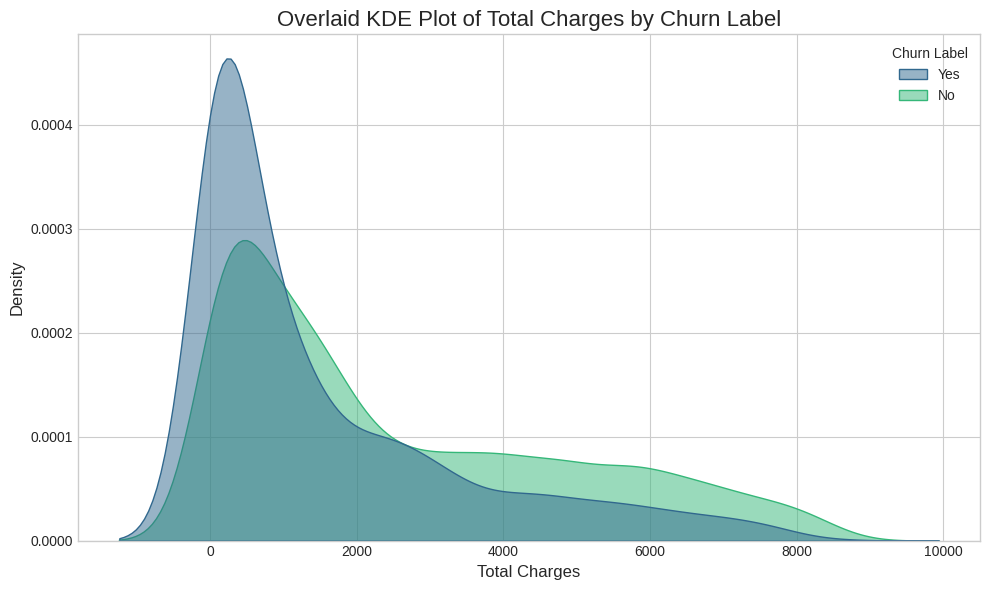

In [45]:
plot_overlaid_distribution(df, 'Total Charges', 'Churn Label', plot_type='kde')

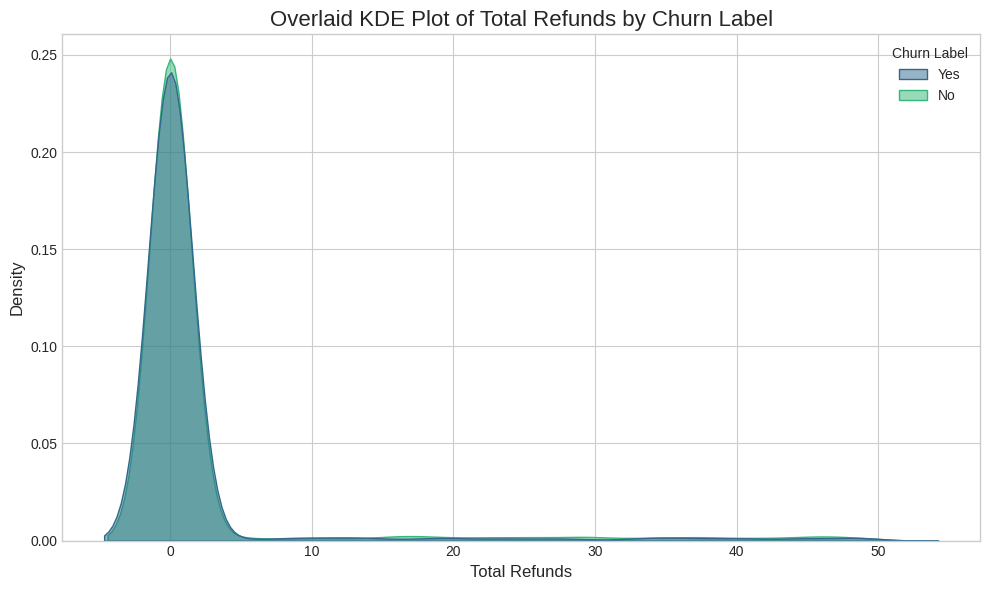

In [46]:
plot_overlaid_distribution(df, 'Total Refunds', 'Churn Label', plot_type='kde')

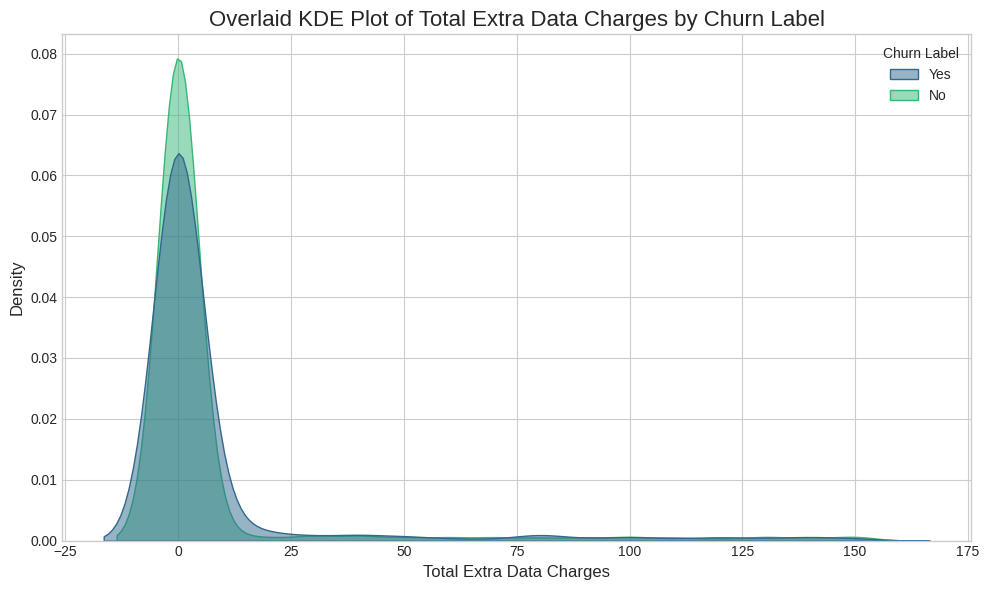

In [47]:
plot_overlaid_distribution(df, 'Total Extra Data Charges', 'Churn Label', plot_type='kde')

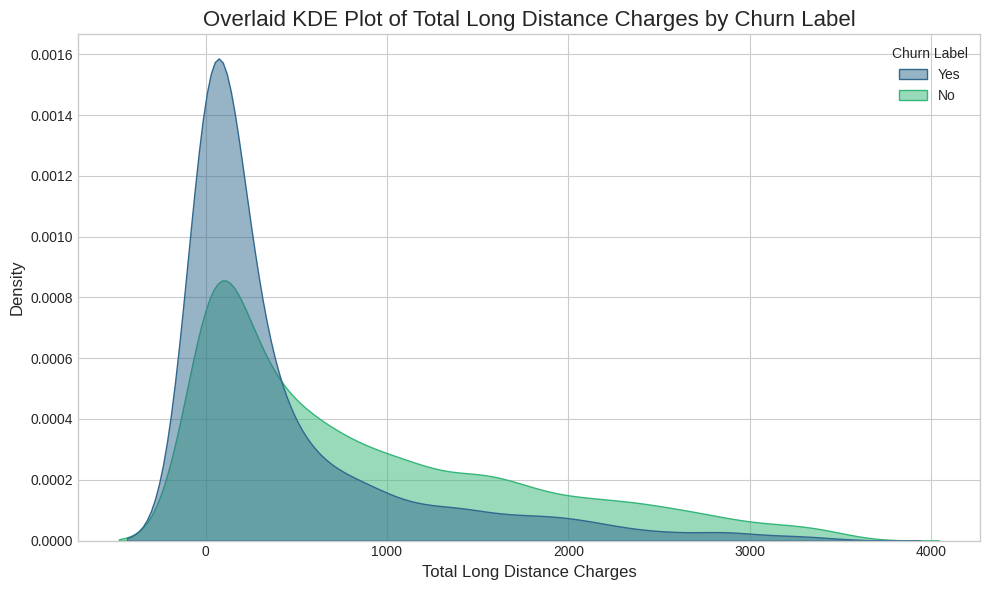

In [48]:
plot_overlaid_distribution(df, 'Total Long Distance Charges', 'Churn Label', plot_type='kde')

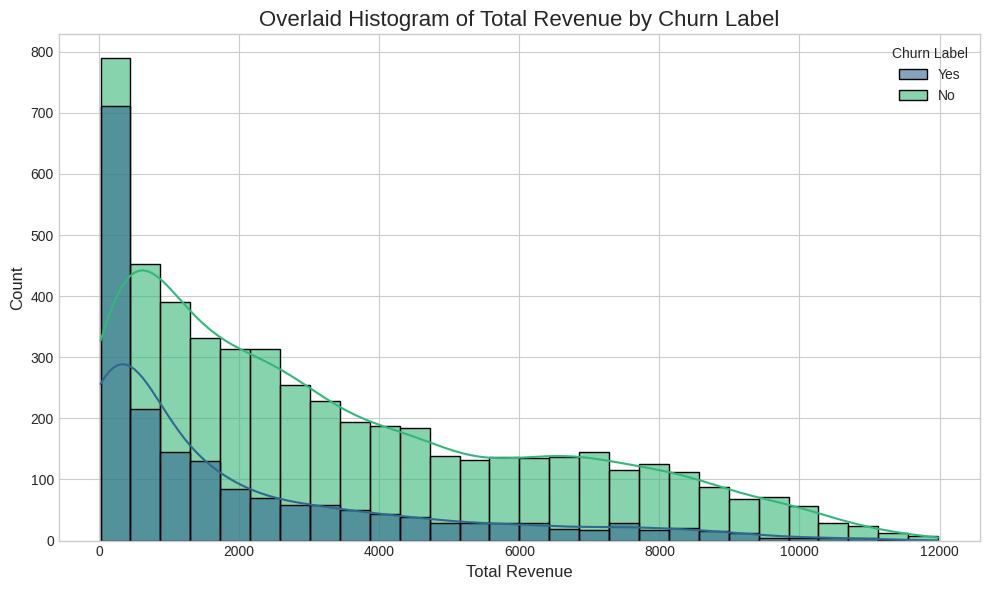

In [49]:
plot_overlaid_distribution(df, 'Total Revenue', 'Churn Label', plot_type='hist')

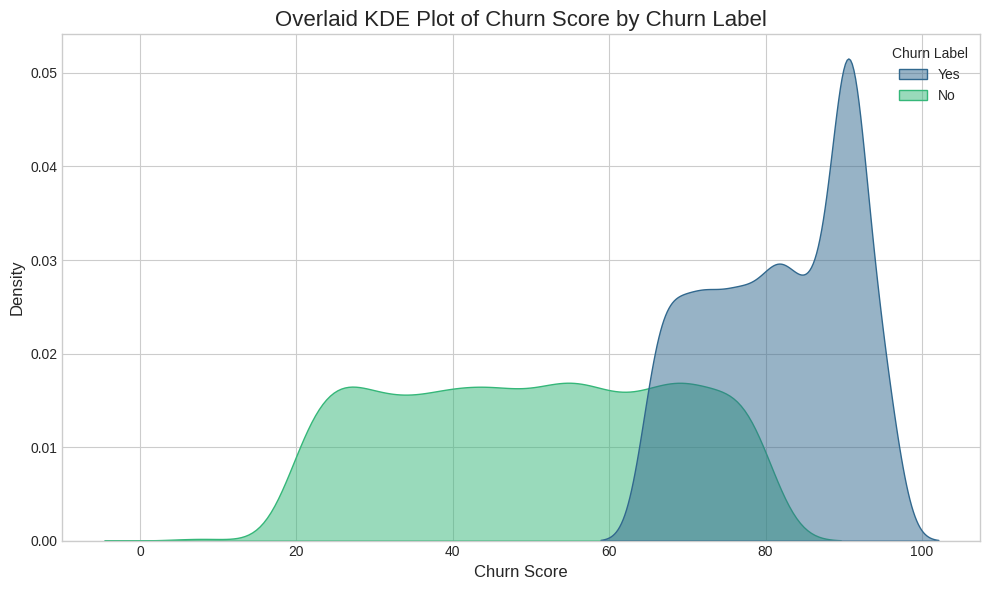

In [50]:
plot_overlaid_distribution(df, 'Churn Score', 'Churn Label', plot_type='kde')

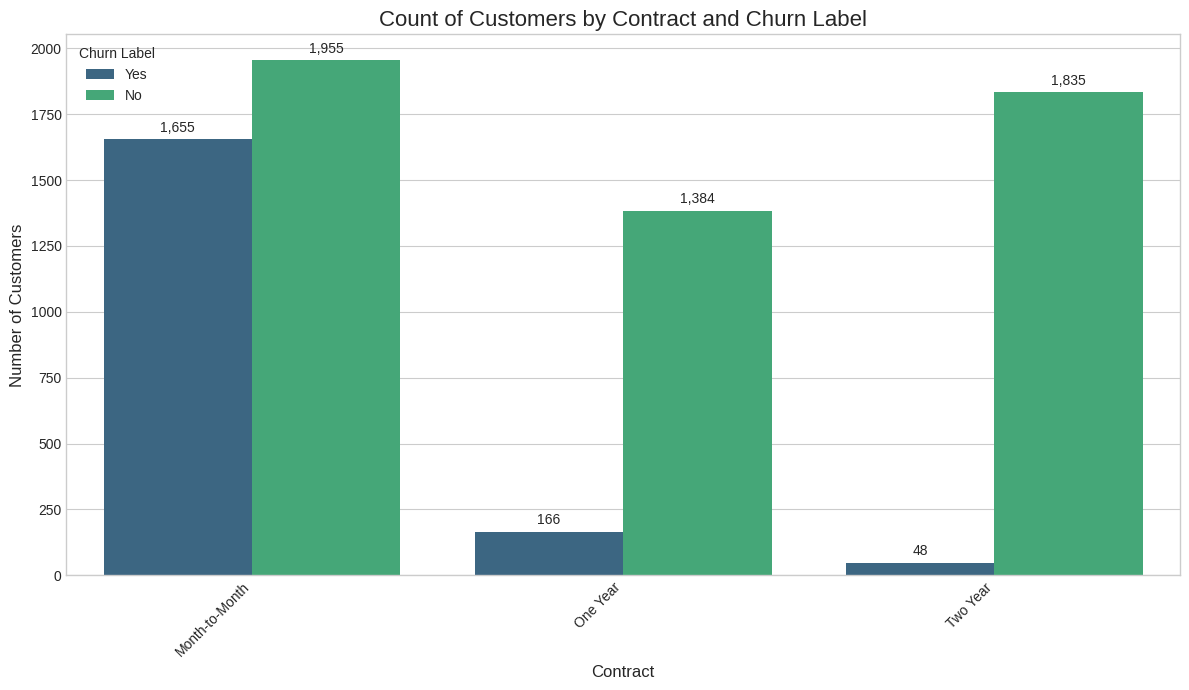

In [51]:
plot_countplot(df,"Contract","Churn Label")

<b>Primary Source of Churn:</b> The overwhelming majority of customer churn originates from the Month-to-Month contract segment. This group alone accounts for 1,655 churned customers, which is dramatically higher than the other contract types combined.

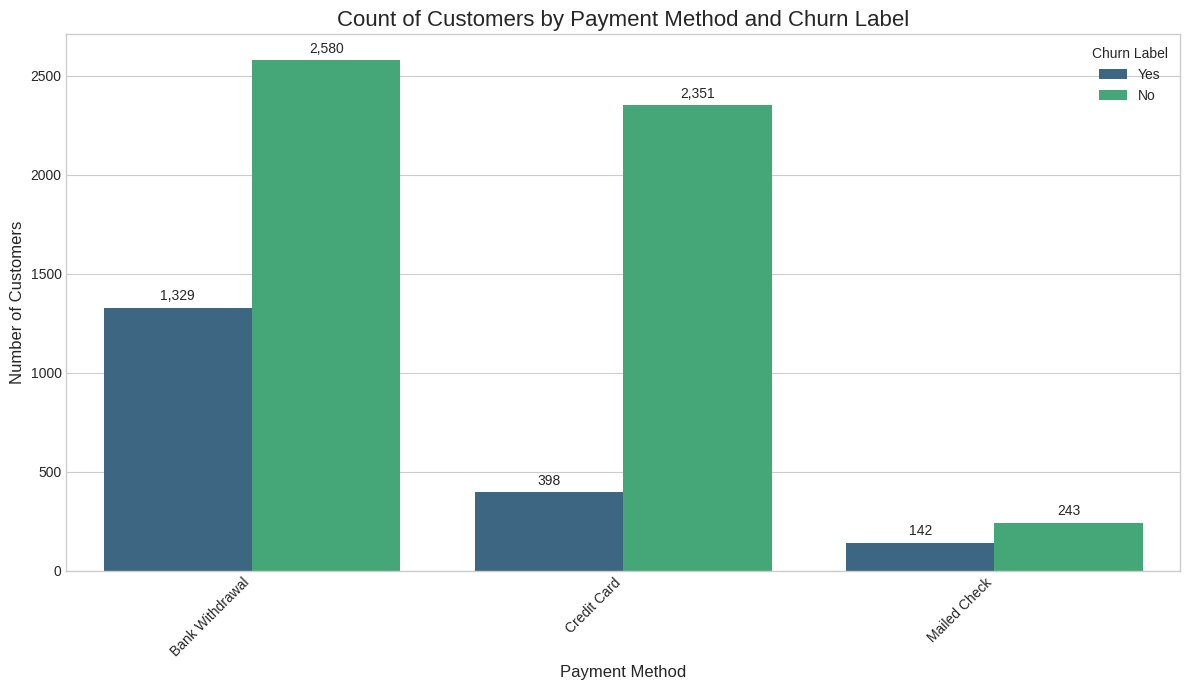

In [52]:
plot_countplot(df,"Payment Method","Churn Label")

<ul><li>Bank Withdrawal is the primary source of churn by absolute volume, with more customers leaving from this segment than all others combined.</li>

<li>Credit Card users are significantly more stable, showing a much lower churn rate compared to other payment methods.</li>

<li>Mailed Check has the highest relative churn rate, making it a high-friction and high-risk payment option for customer retention.</li>

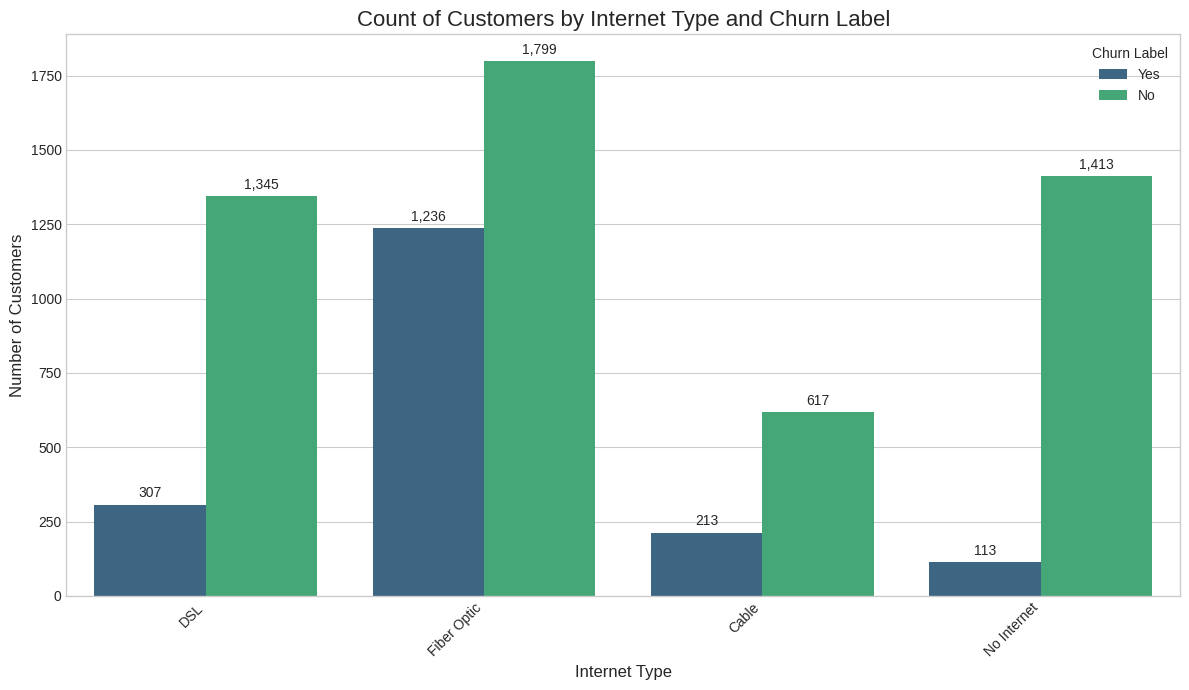

In [53]:
plot_countplot(df,"Internet Type","Churn Label")

Fiber Optic represents a high-risk service. The churn rate for Fiber Optic is alarmingly high, with the number of churners (1,236) being a substantial fraction of retained customers (1,799). This suggests potential issues with pricing, service reliability, or value proposition for this specific offering.

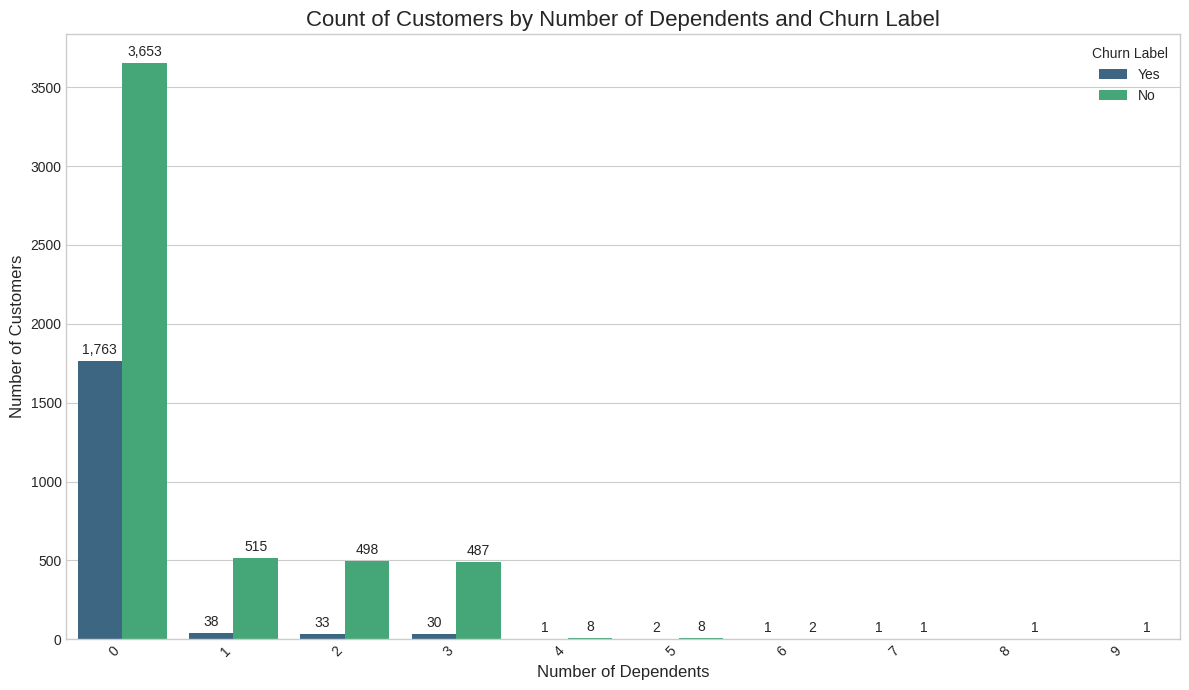

In [54]:
plot_countplot(df,"Number of Dependents","Churn Label")

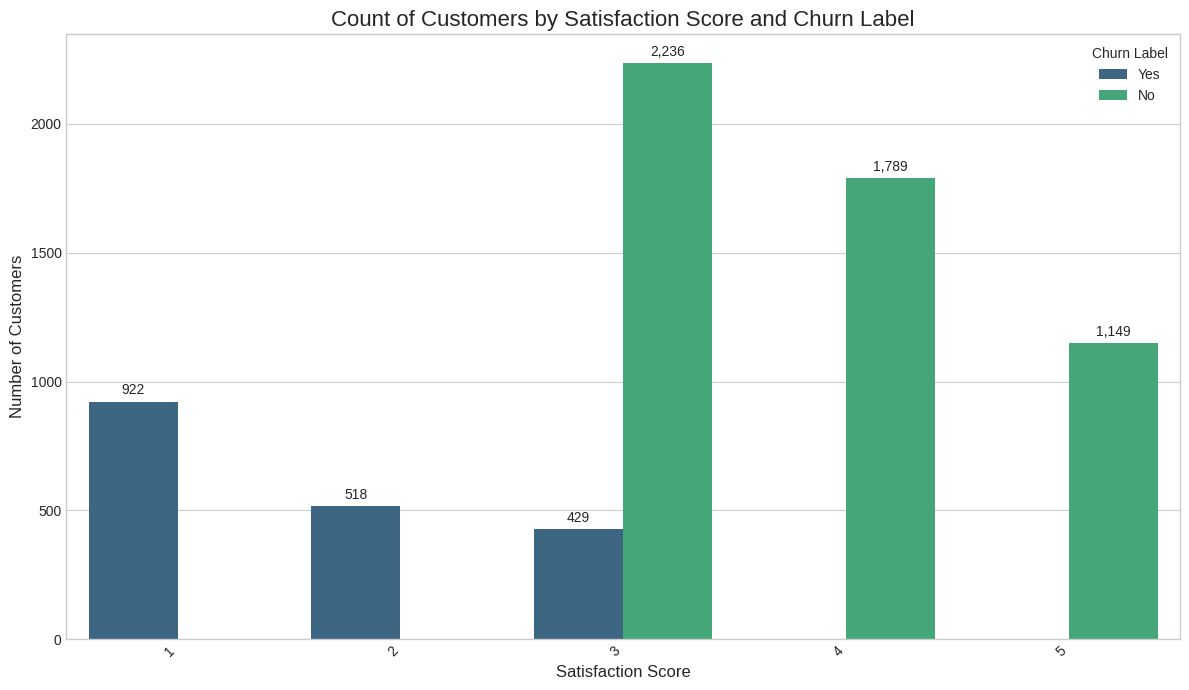

In [55]:
plot_countplot(df,"Satisfaction Score","Churn Label")

<div style="background: linear-gradient(135deg, #4F46E5 0%, #7C3AED 100%);margin-top: 10px; margin-bottom: 5px;padding: 5px 10px;border-radius: 12px; text-align: left; box-shadow: 0 10px 25px rgba(0, 0, 0, 0.1);">
        <h2 style="font-size: 1.8em; color: white; border-bottom: 2px solid #e5e7eb; padding-bottom: 10px; margin-bottom: 20px; display: flex; align-items: center; font-weight: 600;">
            <span style="font-size: 1.2em; margin-right: 12px;">6.</span>Feature Correlation Analysis
        </h2>
    </div>

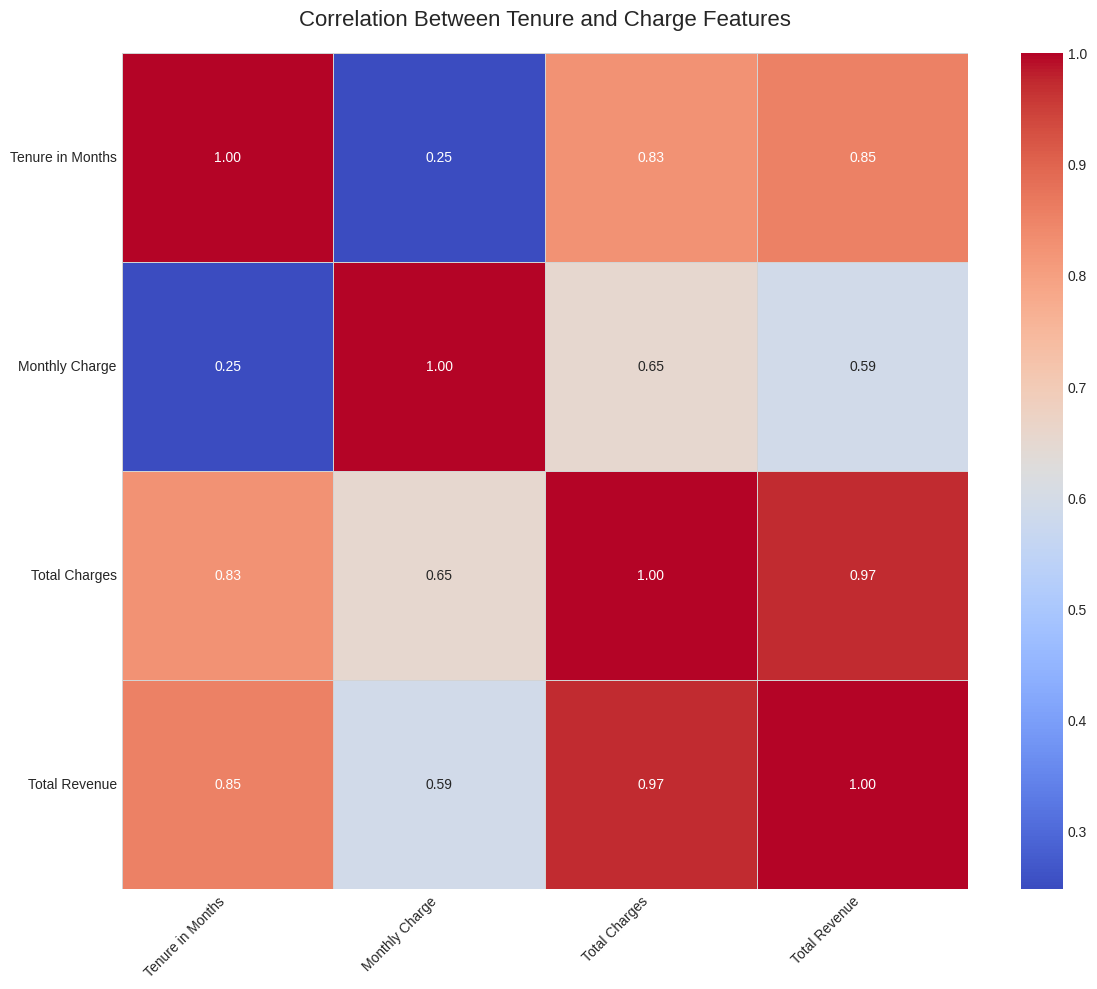

In [56]:
correlated_features = [
    'Tenure in Months',
    'Monthly Charge',
    'Total Charges',
    'Total Revenue'
]

plot_correlation_heatmap(df, correlated_features, title="Correlation Between Tenure and Charge Features")

<div style="background: linear-gradient(135deg, #4F46E5 0%, #7C3AED 100%);margin-top: 10px; margin-bottom: 5px;padding: 5px 10px;border-radius: 12px; text-align: left; box-shadow: 0 10px 25px rgba(0, 0, 0, 0.1);">
        <h2 style="font-size: 1.8em; color: white; border-bottom: 2px solid #e5e7eb; padding-bottom: 10px; margin-bottom: 20px; display: flex; align-items: center; font-weight: 600;">
            <span style="font-size: 1.2em; margin-right: 12px;">7.</span>Summary of Key Insights
        </h2>
    </div>

<div style="font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, 'Helvetica Neue', Arial, sans-serif; background-color: #f9fafb; color: #374151; line-height: 1.7; max-width: 1000px; margin: 30px auto; padding: 20px;">
<div style="text-align: center; border-bottom: 2px solid #e5e7eb; padding-bottom: 20px; margin-bottom: 40px;">
        <h1 style="font-size: 2.5em; color: #111827; margin: 0;">Summary of Insights: Customer Churn EDA</h1>
        <p style="font-size: 1.2em; color: #6b7280;">Key drivers and customer profiles identified from the data.</p>
    </div>
<div style="background-color: #ffffff; border-radius: 12px; box-shadow: 0 8px 25px rgba(0, 0, 0, 0.07); margin-bottom: 35px; padding: 30px; border: 1px solid #e5e7eb; overflow: hidden;">
        <h2 style="font-size: 1.6em; color: #1f2937; margin-top: 0; display: flex; align-items: center;">
            <span style="font-size: 1.8em; margin-right: 15px; line-height: 1;">📜</span>Contract & Financials are King
        </h2>
        <ul style="list-style-type: none; padding-left: 0;">
            <li style="position: relative; padding-left: 25px; margin-bottom: 12px; font-size: 1.05em;"><span style="position: absolute; left: 0; color: #10b981; font-weight: bold;">✓</span><strong>The Strongest Signal:</strong> Contract type is the most powerful predictor. Customers on flexible <strong>Month-to-Month</strong> plans represent the overwhelming majority of churners.</li>
            <li style="position: relative; padding-left: 25px; margin-bottom: 12px; font-size: 1.05em;"><span style="position: absolute; left: 0; color: #10b981; font-weight: bold;">✓</span><strong>Payment Friction:</strong> The choice of payment method matters. <strong>Bank Withdrawal</strong> is associated with a much higher churn rate compared to the stability of <strong>Credit Card</strong> payments.</li>
            <li style="position: relative; padding-left: 25px; margin-bottom: 12px; font-size: 1.05em;"><span style="position: absolute; left: 0; color: #10b981; font-weight: bold;">✓</span><strong>Price Sensitivity:</strong> High <strong>Monthly Charges</strong>, especially for services like <strong>Fiber Optic</strong>, are a major catalyst for churn, suggesting a perceived mismatch between cost and value.</li>
        </ul>
    </div>
<div style="background-color: #ffffff; border-radius: 12px; box-shadow: 0 8px 25px rgba(0, 0, 0, 0.07); margin-bottom: 35px; padding: 30px; border: 1px solid #e5e7eb; overflow: hidden;">
        <h2 style="font-size: 1.6em; color: #1f2937; margin-top: 0; display: flex; align-items: center;">
            <span style="font-size: 1.8em; margin-right: 15px; line-height: 1;">🛁</span>The "Bathtub" Curve of Customer Loyalty
        </h2>
        <ul style="list-style-type: none; padding-left: 0;">
            <li style="position: relative; padding-left: 25px; margin-bottom: 12px; font-size: 1.05em;"><span style="position: absolute; left: 0; color: #10b981; font-weight: bold;">✓</span><strong>Critical Onboarding Phase:</strong> The risk of churn is highest in the <strong>first few months</strong>. A customer who will churn is most likely to do so early in their lifecycle.</li>
            <li style="position: relative; padding-left: 25px; margin-bottom: 12px; font-size: 1.05em;"><span style="position: absolute; left: 0; color: #10b981; font-weight: bold;">✓</span><strong>Mid-Life Stability:</strong> Customers who make it past the initial period enter a "loyalty zone" (approx. 20-60 months) where their churn risk is at its lowest.</li>
            <li style="position: relative; padding-left: 25px; margin-bottom: 12px; font-size: 1.05em;"><span style="position: absolute; left: 0; color: #10b981; font-weight: bold;">✓</span><strong>End-of-Contract Re-evaluation:</strong> A smaller churn spike occurs at very long tenures (60+ months), likely as long-term contracts expire and loyal customers reassess their options.</li>
        </ul>
    </div>

<div style="background-color: #ffffff; border-radius: 12px; box-shadow: 0 8px 25px rgba(0, 0, 0, 0.07); margin-bottom: 35px; padding: 30px; border: 1px solid #e5e7eb; overflow: hidden;">
        <h2 style="font-size: 1.6em; color: #1f2937; margin-top: 0; display: flex; align-items: center;">
            <span style="font-size: 1.8em; margin-right: 15px; line-height: 1;">🔗</span>Service Engagement & Dependencies Signal Stickiness
        </h2>
        <ul style="list-style-type: none; padding-left: 0;">
            <li style="position: relative; padding-left: 25px; margin-bottom: 12px; font-size: 1.05em;"><span style="position: absolute; left: 0; color: #10b981; font-weight: bold;">✓</span><strong>Value-Added Services:</strong> A lack of engagement with protective add-ons like <strong>Premium Tech Support</strong> is a strong indicator of churn. Customers who subscribe to these are more invested.</li>
            <li style="position: relative; padding-left: 25px; margin-bottom: 12px; font-size: 1.05em;"><span style="position: absolute; left: 0; color: #10b981; font-weight: bold;">✓</span><strong>Life Circumstances:</strong> Customers with real-world ties, such as having <strong>Dependents</strong> or having made <strong>Referrals</strong>, are significantly less likely to leave.</li>
            <li style="position: relative; padding-left: 25px; margin-bottom: 12px; font-size: 1.05em;"><span style="position: absolute; left: 0; color: #10b981; font-weight: bold;">✓</span><strong>Satisfaction is a Cliff:</strong> Low <strong>Satisfaction Scores</strong> (1-3) are almost exclusively held by customers who churned. A score below 4 represents an immediate, high-priority churn risk.</li>
        </ul>
    </div>

<div style="background-color: #ffffff; border-radius: 12px; box-shadow: 0 8px 25px rgba(0, 0, 0, 0.07); margin-bottom: 35px; padding: 30px; border: 1px solid #e5e7eb; overflow: hidden;">
        <h2 style="font-size: 1.6em; color: #1f2937; margin-top: 0; display: flex; align-items: center;">
            <span style="font-size: 1.8em; margin-right: 15px; line-height: 1;">👤</span>The Archetypal Customer Profiles
        </h2>
        <div style="display: grid; grid-template-columns: repeat(auto-fit, minmax(300px, 1fr)); gap: 30px; margin-top: 20px;">
            <div style="padding: 25px; border-radius: 10px; border: 2px solid #fecaca; background-color: #fef2f2;">
                <h3 style="margin-top: 0; font-size: 1.3em; display: flex; align-items: center; color: #dc2626;"><span style="font-size: 1.8em; margin-right: 15px; line-height: 1;">🔥</span>High-Risk Churner</h3>
                <ul style="list-style-type: none; padding-left: 0; margin-bottom: 0;">
                    <li style="position: relative; padding-left: 25px; margin-bottom: 12px; font-size: 1.05em;"><span style="position: absolute; left: 0; color: #dc2626; font-weight: bold;">-</span>On a Month-to-Month contract</li>
                    <li style="position: relative; padding-left: 25px; margin-bottom: 12px; font-size: 1.05em;"><span style="position: absolute; left: 0; color: #dc2626; font-weight: bold;">-</span>Has Fiber Optic internet</li>
                    <li style="position: relative; padding-left: 25px; margin-bottom: 12px; font-size: 1.05em;"><span style="position: absolute; left: 0; color: #dc2626; font-weight: bold;">-</span>Pays a high monthly bill</li>
                    <li style="position: relative; padding-left: 25px; margin-bottom: 12px; font-size: 1.05em;"><span style="position: absolute; left: 0; color: #dc2626; font-weight: bold;">-</span>Lacks add-ons like Premium Support</li>
                    <li style="position: relative; padding-left: 25px; margin-bottom: 12px; font-size: 1.05em;"><span style="position: absolute; left: 0; color: #dc2626; font-weight: bold;">-</span>Has a low Satisfaction Score (1-3)</li>
                    <li style="position: relative; padding-left: 25px; margin-bottom: 12px; font-size: 1.05em;"><span style="position: absolute; left: 0; color: #dc2626; font-weight: bold;">-</span>No dependents or referrals</li>
                </ul>
            </div>
            <div style="padding: 25px; border-radius: 10px; border: 2px solid #a7f3d0; background-color: #f0fdf4;">
                <h3 style="margin-top: 0; font-size: 1.3em; display: flex; align-items: center; color: #059669;"><span style="font-size: 1.8em; margin-right: 15px; line-height: 1;">🛡️</span>Loyal Customer</h3>
                <ul style="list-style-type: none; padding-left: 0; margin-bottom: 0;">
                    <li style="position: relative; padding-left: 25px; margin-bottom: 12px; font-size: 1.05em;"><span style="position: absolute; left: 0; color: #059669; font-weight: bold;">+</span>On a Two-Year contract</li>
                    <li style="position: relative; padding-left: 25px; margin-bottom: 12px; font-size: 1.05em;"><span style="position: absolute; left: 0; color: #059669; font-weight: bold;">+</span>Has dependents and has made referrals</li>
                    <li style="position: relative; padding-left: 25px; margin-bottom: 12px; font-size: 1.05em;"><span style="position: absolute; left: 0; color: #059669; font-weight: bold;">+</span>Uses add-on services</li>
                    <li style="position: relative; padding-left: 25px; margin-bottom: 12px; font-size: 1.05em;"><span style="position: absolute; left: 0; color: #059669; font-weight: bold;">+</span>Has a high Satisfaction Score (4-5)</li>
                    <li style="position: relative; padding-left: 25px; margin-bottom: 12px; font-size: 1.05em;"><span style="position: absolute; left: 0; color: #059669; font-weight: bold;">+</span>Long tenure with the company</li>
                    <li style="position: relative; padding-left: 25px; margin-bottom: 12px; font-size: 1.05em;"><span style="position: absolute; left: 0; color: #059669; font-weight: bold;">+</span>Pays via Credit Card</li>
                </ul>
            </div>
        </div>
    </div>

</div>


<div style="background: linear-gradient(135deg, #4F46E5 0%, #7C3AED 100%);margin-top: 10px; margin-bottom: 5px;padding: 5px 10px;border-radius: 12px; text-align: left; box-shadow: 0 10px 25px rgba(0, 0, 0, 0.1);">
        <h2 style="font-size: 1.8em; color: white; border-bottom: 2px solid #e5e7eb; padding-bottom: 10px; margin-bottom: 20px; display: flex; align-items: center; font-weight: 600;">
            <span style="font-size: 1.2em; margin-right: 12px;">8.</span>Final Feature Selection for Modeling
        </h2>
    </div>

 <div style="font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, 'Helvetica Neue', Arial, sans-serif; background-color: #f8f9fa; color: #333; line-height: 1.6; max-width: 950px; margin: 20px auto; padding: 15px;">

<div style="text-align: center; border-bottom: 2px solid #e9ecef; padding-bottom: 15px; margin-bottom: 30px;">
        <h1 style="margin: 0; color: #212529; font-size: 2em;">Final Feature Selection for Churn Prediction</h1>
        <p style="font-size: 1.1em; color: #6c757d;">Based on Exploratory Data Analysis (EDA), the following features are selected for the model.</p>
    </div>
<div style="background: #ffffff; border-radius: 12px; box-shadow: 0 6px 15px rgba(0,0,0,0.08); margin-bottom: 30px; padding: 25px 30px; border-left: 5px solid #28a745;">
        <h2 style="margin-top: 0; font-size: 1.5em; display: flex; align-items: center; color: #28a745;">
            <span style="font-size: 1.5em; margin-right: 15px;">✔</span>Recommended Final Feature List (21)
        </h2>
        <div style="display: grid; grid-template-columns: repeat(auto-fill, minmax(250px, 1fr)); gap: 20px;">
            <div class="feature-group">
                <h3 style="font-size: 1.1em; color: #495057; border-bottom: 1px solid #dee2e6; padding-bottom: 8px; margin-top: 0;">Customer Demographics</h3>
                <ul style="list-style-type: none; padding-left: 0; margin: 0;">
                    <li style="padding: 6px 0; border-bottom: 1px solid #f1f3f5;">Senior Citizen</li>
                    <li style="padding: 6px 0; border-bottom: 1px solid #f1f3f5;">Under 30</li>
                    <li style="padding: 6px 0; border-bottom: 1px solid #f1f3f5;">Dependents</li>
                    <li style="padding: 6px 0; border-bottom: none;">Referrals</li>
                </ul>
            </div>
            <div class="feature-group">
                <h3 style="font-size: 1.1em; color: #495057; border-bottom: 1px solid #dee2e6; padding-bottom: 8px; margin-top: 0;">Account & Contract</h3>
                <ul style="list-style-type: none; padding-left: 0; margin: 0;">
                    <li style="padding: 6px 0; border-bottom: 1px solid #f1f3f5;">Tenure in Months</li>
                    <li style="padding: 6px 0; border-bottom: 1px solid #f1f3f5;">Contract</li>
                    <li style="padding: 6px 0; border-bottom: 1px solid #f1f3f5;">Payment Method</li>
                    <li style="padding: 6px 0; border-bottom: 1px solid #f1f3f5;">Paperless Billing</li>
                    <li style="padding: 6px 0; border-bottom: 1px solid #f1f3f5;">Monthly Charge</li>
                    <li style="padding: 6px 0; border-bottom: none;">Offer</li>
                </ul>
            </div>
            <div class="feature-group">
                <h3 style="font-size: 1.1em; color: #495057; border-bottom: 1px solid #dee2e6; padding-bottom: 8px; margin-top: 0;">Service Usage & Feedback</h3>
                <ul style="list-style-type: none; padding-left: 0; margin: 0;">
                    <li style="padding: 6px 0; border-bottom: 1px solid #f1f3f5;">Internet Type</li>
                    <li style="padding: 6px 0; border-bottom: 1px solid #f1f3f5;">Avg Monthly GB Download</li>
                    <li style="padding: 6px 0; border-bottom: 1px solid #f1f3f5;">Premium Tech Support</li>
                    <li style="padding: 6px 0; border-bottom: 1px solid #f1f3f5;">Unlimited Data</li>
                    <li style="padding: 6px 0; border-bottom: 1px solid #f1f3f5;">Multiple Lines</li>
                    <li style="padding: 6px 0; border-bottom: 1px solid #f1f3f5;">Online Backup</li>
                    <li style="padding: 6px 0; border-bottom: 1px solid #f1f3f5;">Device Protection Plan</li>
                    <li style="padding: 6px 0; border-bottom: 1px solid #f1f3f5;">Streaming TV</li>
                    <li style="padding: 6px 0; border-bottom: 1px solid #f1f3f5;">Streaming Movies</li>
                    <li style="padding: 6px 0; border-bottom: 1px solid #f1f3f5;">Streaming Music</li>
                    <li style="padding: 6px 0; border-bottom: none;">Satisfaction Score</li>
                </ul>
            </div>
        </div>
    </div>

<div style="background: #ffffff; border-radius: 12px; box-shadow: 0 6px 15px rgba(0,0,0,0.08); margin-bottom: 30px; padding: 25px 30px; border-left: 5px solid #dc3545;">
        <h2 style="margin-top: 0; font-size: 1.5em; display: flex; align-items: center; color: #dc3545;">
            <span style="font-size: 1.5em; margin-right: 15px;">✘</span>Excluded Features & Justification
        </h2>
        <div style="display: grid; grid-template-columns: repeat(auto-fill, minmax(250px, 1fr)); gap: 20px;">
            <div class="feature-group">
                <h3 style="font-size: 1.1em; color: #495057; border-bottom: 1px solid #dee2e6; padding-bottom: 8px; margin-top: 0;">Reason: Data Leakage</h3>
                <p style="font-style: italic; color: #6c757d; font-size: 0.95em; margin-top: -10px; margin-bottom: 15px; padding: 10px; background-color: #f8f9fa; border-radius: 6px;">These features contain information about the future, which is unavailable at the time of prediction.</p>
                <ul style="list-style-type: none; padding-left: 0; margin: 0;">
                    <li style="padding: 6px 0; border-bottom: 1px solid #f1f3f5;">Churn Score</li>
                    <li style="padding: 6px 0; border-bottom: 1px solid #f1f3f5;">Customer Status</li>
                    <li style="padding: 6px 0; border-bottom: 1px solid #f1f3f5;">Churn Category & Reason</li>
                    <li style="padding: 6px 0; border-bottom: none;">CLTV</li>
                </ul>
            </div>
            <div class="feature-group">
                <h3 style="font-size: 1.1em; color: #495057; border-bottom: 1px solid #dee2e6; padding-bottom: 8px; margin-top: 0;">Reason: High Correlation</h3>
                <p style="font-style: italic; color: #6c757d; font-size: 0.95em; margin-top: -10px; margin-bottom: 15px; padding: 10px; background-color: #f8f9fa; border-radius: 6px;">These are redundant. We keep the most direct feature (e.g., Tenure) to avoid multicollinearity.</p>
                <ul style="list-style-type: none; padding-left: 0; margin: 0;">
                    <li style="padding: 6px 0; border-bottom: 1px solid #f1f3f5;">Total Charges</li>
                    <li style="padding: 6px 0; border-bottom: 1px solid #f1f3f5;">Total Revenue</li>
                    <li style="padding: 6px 0; border-bottom: 1px solid #f1f3f5;">Number of Dependents</li>
                    <li style="padding: 6px 0; border-bottom: 1px solid #f1f3f5;">Number of Refrals</li>
                    <li style="padding: 6px 0; border-bottom: none;">Age</li>
                </ul>
            </div>
            <div class="feature-group">
                <h3 style="font-size: 1.1em; color: #495057; border-bottom: 1px solid #dee2e6; padding-bottom: 8px; margin-top: 0;">Reason: Poor Predictors</h3>
                <p style="font-style: italic; color: #6c757d; font-size: 0.95em; margin-top: -10px; margin-bottom: 15px; padding: 10px; background-color: #f8f9fa; border-radius: 6px;">These features showed little to no relationship with customer churn during EDA.</p>
                <ul style="list-style-type: none; padding-left: 0; margin: 0;">
                    <li style="padding: 6px 0; border-bottom: 1px solid #f1f3f5;">Gender</li>
                    <li style="padding: 6px 0; border-bottom: 1px solid #f1f3f5;">Phone Service</li>
                    <li style="padding: 6px 0; border-bottom: 1px solid #f1f3f5;">Population</li>
                    <li style="padding: 6px 0; border-bottom: 1px solid #f1f3f5;">All Refund/Extra Charge Columns</li>
                    <li style="padding: 6px 0; border-bottom: none;">Avg Monthly Long Distance Charges</li>
                </ul>
            </div>
            <div class="feature-group">
                <h3 style="font-size: 1.1em; color: #495057; border-bottom: 1px solid #dee2e6; padding-bottom: 8px; margin-top: 0;">Reason: Identifiers & Unused</h3>
                <p style="font-style: italic; color: #6c757d; font-size: 0.95em; margin-top: -10px; margin-bottom: 15px; padding: 10px; background-color: #f8f9fa; border-radius: 6px;">These are unique IDs, have too many values (high cardinality), or were not found to be useful.</p>
                <ul style="list-style-type: none; padding-left: 0; margin: 0;">
                    <li style="padding: 6px 0; border-bottom: 1px solid #f1f3f5;">Customer ID</li>
                    <li style="padding: 6px 0; border-bottom: 1px solid #f1f3f5;">Country</li>
                    <li style="padding: 6px 0; border-bottom: 1px solid #f1f3f5;">State</li>
                    <li style="padding: 6px 0; border-bottom: none;">Quarter</li>
                </ul>
            </div>
        </div>
    </div>
</div>

